# **TP 2 — TEXT MINING MULTI-DATASETS & MULTILINGUE**

## **Dataset 1: Mono-langue**

### **Load Data**

In [1]:
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import numpy as np
import os

DATASETS_PATH = r"../Datasets/"
CHARTS_OUTPUT_PATH = r"../Charts/Amazon/Multi-langue/"
EMBEDDING_PATH = r"../Embeddings/"
GLOVE_PATH = EMBEDDING_PATH + "glove_100.txt"
GLOVE_DIMS = 100

os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(CHARTS_OUTPUT_PATH, exist_ok=True)
os.makedirs(CHARTS_OUTPUT_PATH + "/Classification/", exist_ok=True)
os.makedirs(CHARTS_OUTPUT_PATH + "/Topic Modeling/", exist_ok=True)
os.makedirs(CHARTS_OUTPUT_PATH, exist_ok=True)
os.makedirs(EMBEDDING_PATH, exist_ok=True)

df = (
    pd.read_csv(DATASETS_PATH + "multilingual_amazon_dataset_2.csv", on_bad_lines="skip")
    .groupby("language", group_keys=False)
    .sample(n=1000, random_state=42)
)
df.head(5)

,product_id,review_id,text,language,rating,sentiment,product_category
1501,product_de_0376556,de_0873803,Der Film war langweilig,de,2,negative,digital_video_download
2586,product_de_0461163,de_0250307,Sehr schöne und grosse Luftballons. Ein echter...,de,3,neutral,toy
2653,product_de_0802121,de_0396078,Die Werkzeuge sind bis auf eine Ausnahme ok. D...,de,3,neutral,home
1055,product_de_0068272,de_0006423,Tolles Lied. ABER nicht mal eine Minute läuft ...,de,2,negative,other
705,product_de_0033642,de_0822473,Dir Pro Version stürzt ständig ab. Bei der Fre...,de,1,negative,other


### **PARTIE 0 — EDA**

#### **General Analysis**

In [2]:
df.describe()

,rating
count,6000.000000
mean,3.013500
std,1.409958
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,5.000000


In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 6000 entries, 1501 to 29535
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   product_id        6000 non-null   str  
 1   review_id         6000 non-null   str  
 2   text              6000 non-null   str  
 3   language          6000 non-null   str  
 4   rating            6000 non-null   int64
 5   sentiment         6000 non-null   str  
 6   product_category  6000 non-null   str  
dtypes: int64(1), str(6)
memory usage: 1.7 MB


In [4]:
df.shape

(6000, 7)

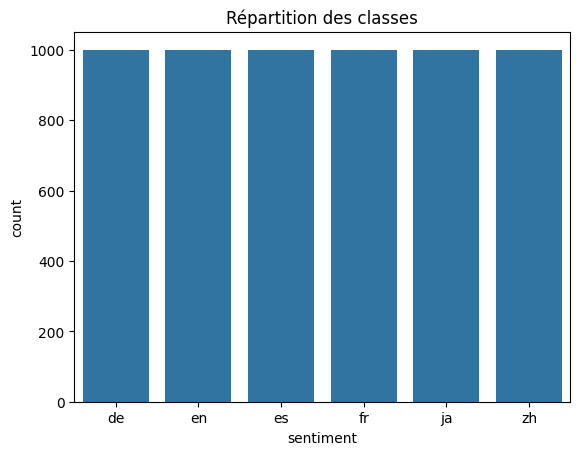

In [5]:
# Visualisation de la distribution des labels (spam vs ham)
sb.countplot(x="language", data=df)
plt.title("Répartition des classes")
plt.xlabel("sentiment")
plt.ylabel("count")
plt.show()

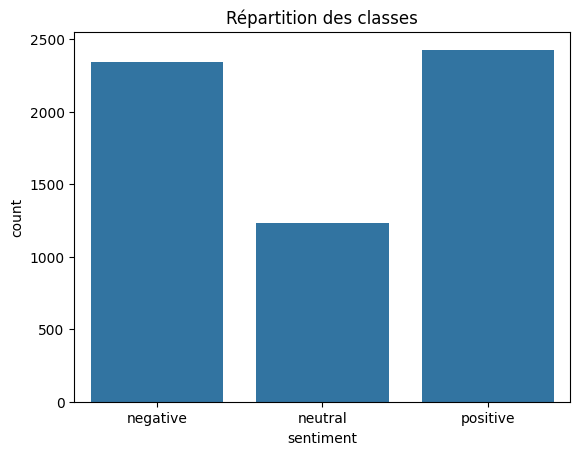

In [6]:
# Visualisation de la distribution des labels (spam vs ham)
sb.countplot(x="sentiment", data=df)
plt.title("Répartition des classes")
plt.xlabel("sentiment")
plt.ylabel("count")
plt.show()

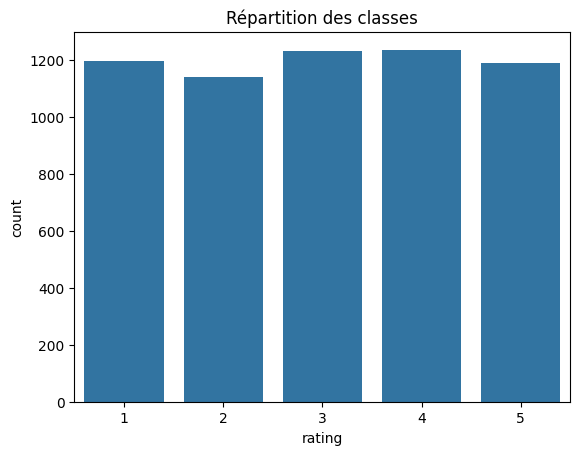

In [7]:
# Visualisation de la distribution des labels (spam vs ham)
sb.countplot(x="rating", data=df)
plt.title("Répartition des classes")
plt.xlabel("rating")
plt.ylabel("count")
plt.show()

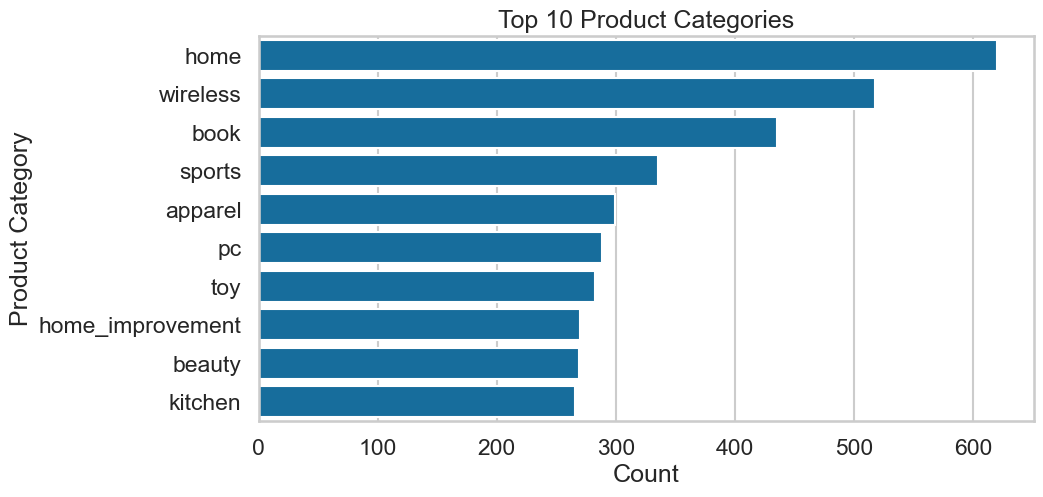

In [66]:
# Top 10 catégories
top10 = df['product_category'].value_counts().head(10)

# Plot
plt.figure(figsize=(10,5))
sb.barplot(x=top10.values, y=top10.index)

plt.title("Top 10 Product Categories")
plt.xlabel("Count")
plt.ylabel("Product Category")
plt.show()

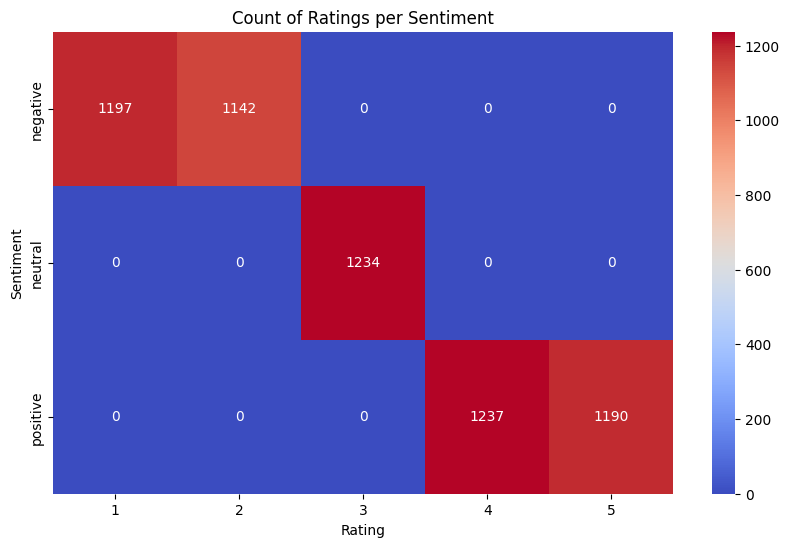

In [9]:
pivot_df = pd.crosstab(df["sentiment"], df["rating"])

plt.rcParams["figure.figsize"] = (10, 6)

sb.heatmap(pivot_df, annot=True, cmap="coolwarm", fmt="d")
plt.title("Count of Ratings per Sentiment")

plt.xlabel("Rating")
plt.ylabel("Sentiment")

plt.savefig(CHARTS_OUTPUT_PATH + "heatmap_counts.png", bbox_inches='tight')
plt.show()

#### **Textual Analysis of reviews**

##### **General Analysis**

In [10]:
eda_df = df.copy()

In [11]:
eda_df["nombre_Caracteres"]=eda_df["text"].apply(lambda x: len(x))
print("Longueur en caracteres :")
print("Min :", eda_df["nombre_Caracteres"].min())
print("Max :", eda_df["nombre_Caracteres"].max())
print("Moyenne :", eda_df["nombre_Caracteres"].mean())


Longueur en caracteres :
Min : 15
Max : 2661
Moyenne : 138.56866666666667


In [12]:
#Longueur des contextes
eda_df["nombre_mots"]=eda_df["text"].apply(lambda x: len(x.split()))
print("Longueur en mots :")
print("Min :", eda_df["nombre_mots"].min())
print("Max :", eda_df["nombre_mots"].max())
print("Moyenne :", eda_df["nombre_mots"].mean())

Longueur en mots :
Min : 1
Max : 482
Moyenne : 20.788333333333334


Longueur en caracteres :
Min : 15
Max : 2661
Moyenne : 138.56866666666667

Longueur en mots :
Min : 1
Max : 482
Moyenne : 20.788333333333334


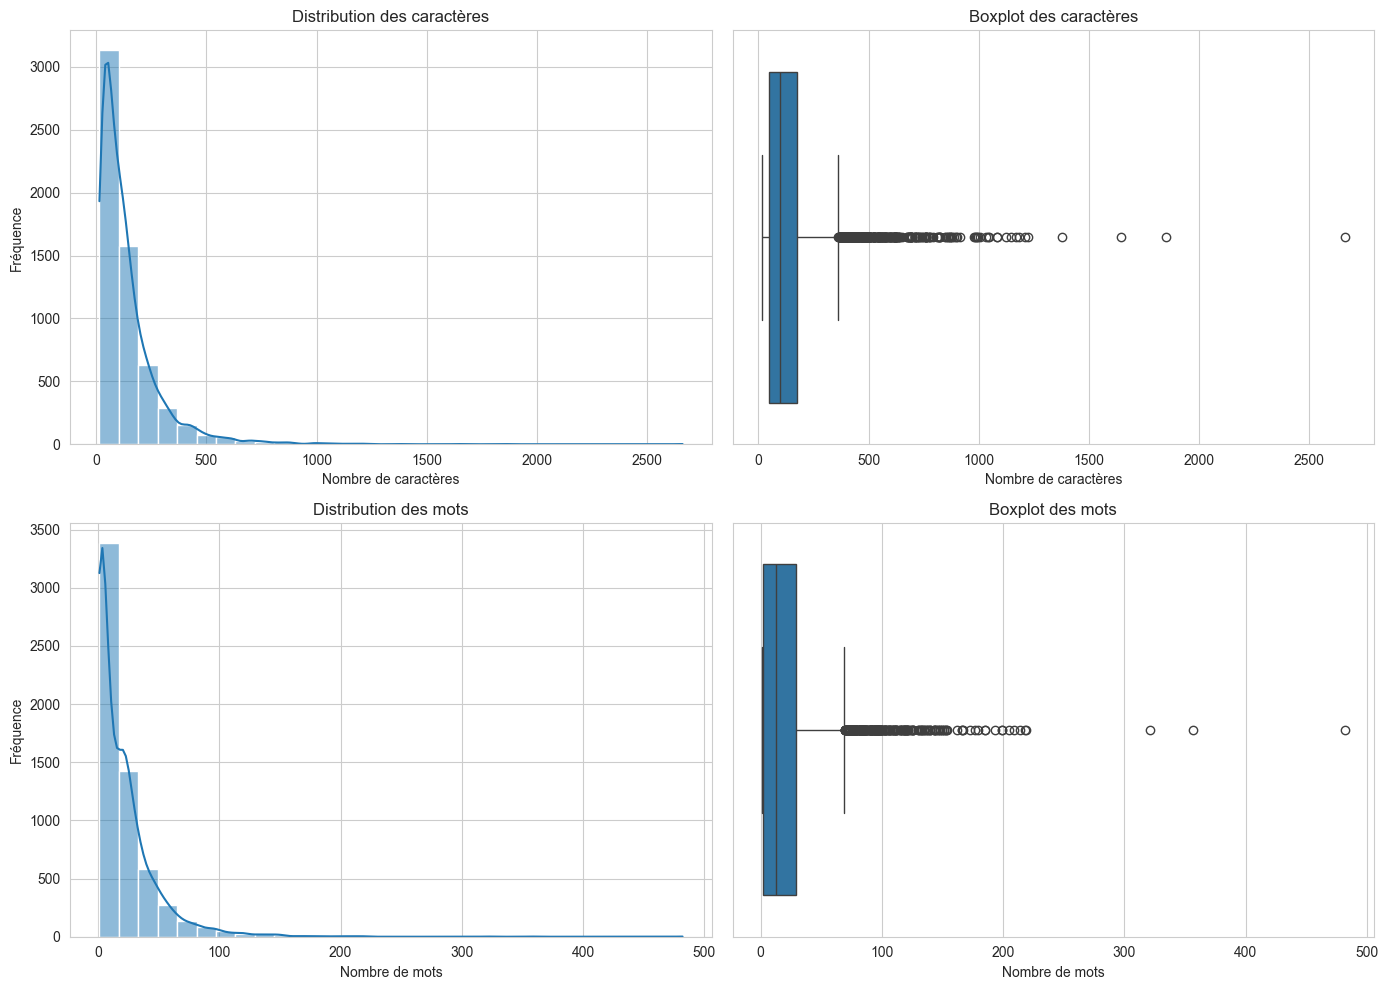

In [13]:
# Calcul des longueurs
eda_df["nombre_Caracteres"] = eda_df["text"].apply(lambda x: len(x))
eda_df["nombre_mots"] = eda_df["text"].apply(lambda x: len(x.split()))

# Affichage des statistiques
print("Longueur en caracteres :")
print("Min :", eda_df["nombre_Caracteres"].min())
print("Max :", eda_df["nombre_Caracteres"].max())
print("Moyenne :", eda_df["nombre_Caracteres"].mean())

print("\nLongueur en mots :")
print("Min :", eda_df["nombre_mots"].min())
print("Max :", eda_df["nombre_mots"].max())
print("Moyenne :", eda_df["nombre_mots"].mean())

# Style seaborn
sb.set_style("whitegrid")

# Création des figures
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# =========================
# Histogramme caractères
# =========================
sb.histplot(
    eda_df["nombre_Caracteres"],
    bins=30,
    kde=True,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Distribution des caractères")
axes[0, 0].set_xlabel("Nombre de caractères")
axes[0, 0].set_ylabel("Fréquence")

# =========================
# Boxplot caractères
# =========================
sb.boxplot(
    x=eda_df["nombre_Caracteres"],
    ax=axes[0, 1]
)

axes[0, 1].set_title("Boxplot des caractères")
axes[0, 1].set_xlabel("Nombre de caractères")

# =========================
# Histogramme mots
# =========================
sb.histplot(
    eda_df["nombre_mots"],
    bins=30,
    kde=True,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Distribution des mots")
axes[1, 0].set_xlabel("Nombre de mots")
axes[1, 0].set_ylabel("Fréquence")

# =========================
# Boxplot mots
# =========================
sb.boxplot(
    x=eda_df["nombre_mots"],
    ax=axes[1, 1]
)

axes[1, 1].set_title("Boxplot des mots")
axes[1, 1].set_xlabel("Nombre de mots")

plt.tight_layout()
plt.savefig(
    os.path.join(CHARTS_OUTPUT_PATH, "Reviews_Textual_EDA.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

##### **Stopwords Analysis**

In [14]:
import nltk
from nltk.corpus import stopwords
nltk.download("stopwords")

english_stopwords = set(stopwords.words("english"))
len(english_stopwords)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\exe\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


198

In [15]:
from bidi.algorithm import get_display

# Compter les Stopwords dans tout les paragraphes
def Analyse_Stopwords(column):
  sw_dict = {}
  for paragraph in column:
    tokens = paragraph.split()
    for word in tokens:
      if word in english_stopwords:
        if word in sw_dict:
          sw_dict[word] += 1
        else:
          sw_dict[word] = 1
  return sw_dict

# Convert to DataFrame
sw_results_dict = Analyse_Stopwords(df["text"])
sw_results_df = pd.DataFrame(list(sw_results_dict.items()), columns=["Stopword", "Frequency"])

# Sort descending
sw_results_df = sw_results_df.sort_values(by="Frequency", ascending=False)

# Changer Textes arabes pour correcte affichage dans matplotlib
sw_results_df


,Stopword,Frequency
25,the,1426
11,a,1392
140,y,959
14,and,918
22,to,906
...,...,...
134,ourselves,1
136,they'll,1
135,we'll,1
138,herself,1


In [16]:
def Analyse_Stopwords_paragraph(paragraph):
  sw_count = 0
  tokens = paragraph.split()
  for word in tokens:
    if word in english_stopwords:
        sw_count += 1
  return sw_count

eda_df["Stopword_Count"] = df["text"].apply(Analyse_Stopwords_paragraph)
eda_df

,product_id,review_id,text,language,rating,sentiment,product_category,nombre_Caracteres,nombre_mots,Stopword_Count
1501,product_de_0376556,de_0873803,Der Film war langweilig,de,2,negative,digital_video_download,23,4,0
2586,product_de_0461163,de_0250307,Sehr schöne und grosse Luftballons. Ein echter...,de,3,neutral,toy,160,24,0
2653,product_de_0802121,de_0396078,Die Werkzeuge sind bis auf eine Ausnahme ok. D...,de,3,neutral,home,196,36,1
1055,product_de_0068272,de_0006423,Tolles Lied. ABER nicht mal eine Minute läuft ...,de,2,negative,other,95,17,0
705,product_de_0033642,de_0822473,Dir Pro Version stürzt ständig ab. Bei der Fre...,de,1,negative,other,74,13,0
...,...,...,...,...,...,...,...,...,...,...
27709,product_zh_0711316,zh_0782223,电池挺好的。挺值的。就是快递再快点就更好了,zh,3,neutral,electronics,21,1,0
26188,product_zh_0563328,zh_0759614,比较鸡肋。而且mac设备的蓝牙仿佛不能识别。,zh,2,negative,other,22,1,0
28911,product_zh_0075461,zh_0067140,文字平实，令人思考建筑的形态和意义，以及极现代和极传统的矛盾,zh,4,positive,book,30,1,0
25370,product_zh_0566024,zh_0675172,没有什么味啊，保养师傅讲有问题啊，内盖都没有,zh,1,negative,automotive,22,1,0


In [17]:
# Counts
stopwords_count = sw_results_df["Frequency"].sum()     # total stopwords
total_words_count = eda_df["nombre_mots"].sum() # total words in corpus

# Values for the pie chart
values = [stopwords_count, total_words_count - stopwords_count]
labels = ["Stopwords", "Autres Mots"]


**Affichage Des Résultats :**

In [18]:
print("Nombre totale des Stopwords : ", sw_results_df["Frequency"].sum())
print("Nombre totale de mots : ", eda_df["nombre_mots"].sum())

Nombre totale des Stopwords :  17584
Nombre totale de mots :  124730


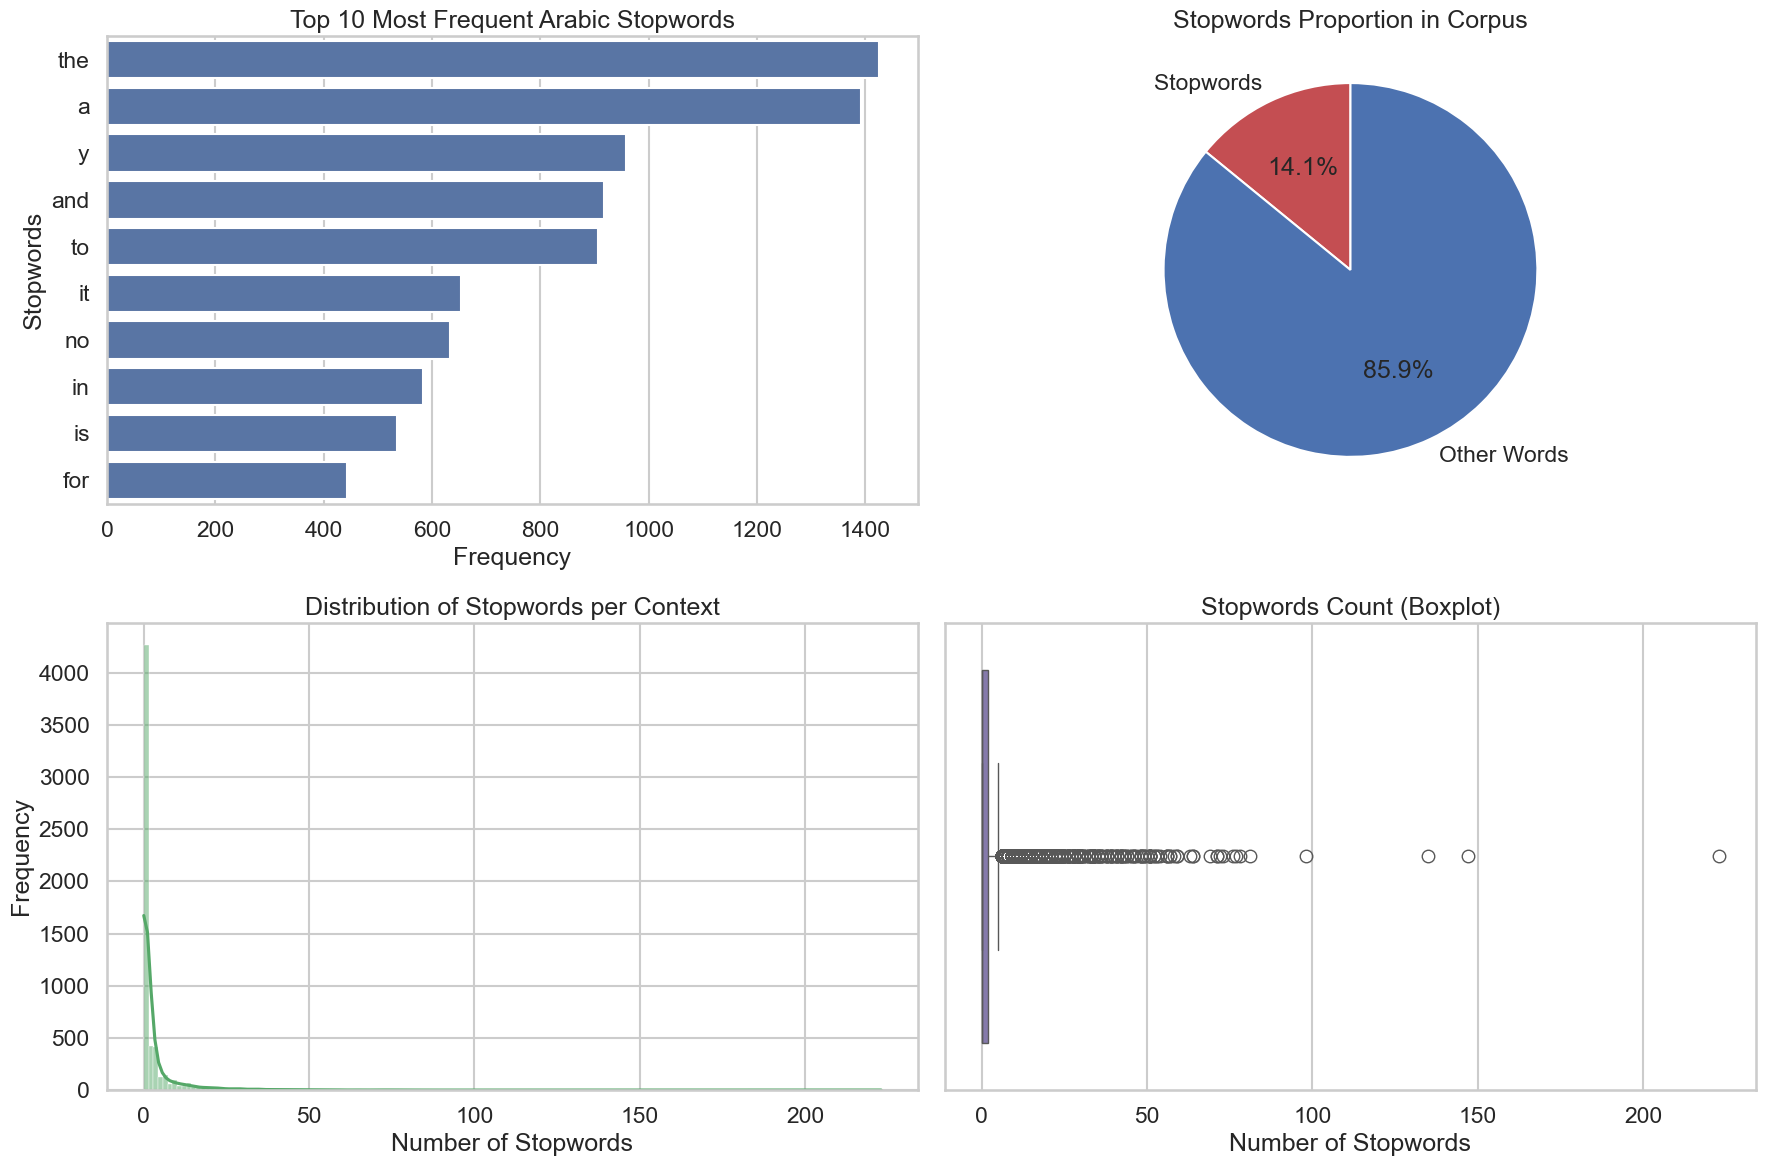

In [19]:
# Professional theme
sb.set_theme(style="whitegrid", context="talk", palette="colorblind")

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

# -------------------------
# 1. Top 10 stopwords
# -------------------------
sb.barplot(
    x="Frequency",
    y="Stopword",
    data=sw_results_df.head(10),
    ax=axes[0],
    color="#4C72B0"  # muted blue
)

axes[0].set_title("Top 10 Most Frequent Arabic Stopwords")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("Stopwords")

# -------------------------
# 2. Stopwords proportion
# -------------------------
stopwords_count = sw_results_df["Frequency"].sum()
total_words_count = eda_df["nombre_mots"].sum()

values = [stopwords_count, total_words_count - stopwords_count]
labels = ["Stopwords", "Other Words"]

axes[1].pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#C44E52", "#4C72B0"]  # muted red & blue
)

axes[1].set_title("Stopwords Proportion in Corpus")

# -------------------------
# 3. Histogram
# -------------------------
sb.histplot(
    eda_df["Stopword_Count"],
    kde=True,
    ax=axes[2],
    color="#55A868"  # muted green
)

axes[2].set_title("Distribution of Stopwords per Context")
axes[2].set_xlabel("Number of Stopwords")
axes[2].set_ylabel("Frequency")

# -------------------------
# 4. Boxplot
# -------------------------
sb.boxplot(
    x=eda_df["Stopword_Count"],
    ax=axes[3],
    color="#8172B3"  # muted purple
)

axes[3].set_title("Stopwords Count (Boxplot)")
axes[3].set_xlabel("Number of Stopwords")

plt.tight_layout()
plt.savefig(CHARTS_OUTPUT_PATH + "Stopwords_Analysis.png", bbox_inches='tight')
plt.show()

### **PARTIE 1 — PRÉTRAITEMENT**

In [20]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import copy
import os
os.environ["TQDM_DISABLE"] = "1"

# Téléchargement et fonction de tokenisation des messages
nltk.download("punkt")

# Suppression des mots vides (stopwords) anglais
nltk.download("stopwords")

def Tokenization(column):
    tokens = column.apply(word_tokenize)
    return tokens

def Delete_StopWords(tokens):
    tokens = tokens.tolist()
    stop_words = set(stopwords.words("english"))
    noStopWords_tokens = copy.deepcopy(tokens)
    
    # Filtrage de chaque liste de tokens
    for i in range(len(noStopWords_tokens)):
        noStopWords_tokens[i] = [word for word in noStopWords_tokens[i] if word not in stop_words]
    return noStopWords_tokens

def Lemmatization(tokens):
    lemmatizer = WordNetLemmatizer()
    lemmatized_tokens = copy.deepcopy(tokens)

    # Réduction de chaque mot à son lemme
    for i in range(len(lemmatized_tokens)):
        lemmatized_tokens[i] = [lemmatizer.lemmatize(word) for word in lemmatized_tokens[i]]
    return lemmatized_tokens



[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\exe\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\exe\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


#### **Pipeline Classique**

In [21]:
# Application du prétraitement minimal (tokenisation seule)
def MinProcessing(data):
    if isinstance(data, pd.DataFrame):
        data = data["text"]

    data = data.astype(str).str.lower()

    return [
        word_tokenize(text)
        for text in data
    ]

#### **Pipeline embedding-friendly**

#### **Pipeline embedding-friendly**

In [22]:
# Pipeline complet : Tokenisation, retrait des Stopwords et Lemmatisation
def AdvancedProcessing(data):
    # Suppression des caractères spéciaux
    adv_preprocessing_data = data["text"].replace(r"[^\w|\s]", "", regex=True)

    # Suppression des emojis
    adv_preprocessing_data = adv_preprocessing_data.replace(r"/(\u00a9|\u00ae|[\u2000-\u3300]|\ud83c[\ud000-\udfff]|\ud83d[\ud000-\udfff]|\ud83e[\ud000-\udfff])/g", "", regex=True)
        
    adv_preprocessing_data = adv_preprocessing_data.str.lower()
    adv_preprocessing_data = Tokenization(adv_preprocessing_data)
    adv_preprocessing_data = Delete_StopWords(adv_preprocessing_data)
    adv_preprocessing_data = Lemmatization(adv_preprocessing_data)
    return adv_preprocessing_data

### **PARTIE 2 — VECTORISATION**

#### **Méthodes classiques**

In [23]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.models import Word2Vec, FastText

def BagOfWords(corpus):
    vectorizer = CountVectorizer(analyzer=lambda x: x, lowercase=False)
    bow = vectorizer.fit_transform(corpus)
    return bow

def TF_IDF(corpus):
    vectorizer = TfidfVectorizer(analyzer=lambda x: x, lowercase=False)
    tfidf = vectorizer.fit_transform(corpus)
    return tfidf


#### **Méthodes embeddings**

In [24]:
def doc_vector(model, doc):
    vectors = [model.wv[w] for w in doc if w in model.wv]
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

def W2V(tokens):
    corpus = tokens.tolist()
    model = Word2Vec(
        sentences=corpus,
        vector_size=100,
        window=5,
        min_count=1,
        workers=4
    )
    return np.array([doc_vector(model, doc) for doc in corpus])

def Fast_Text(tokens):
    corpus = tokens.tolist()
    model = FastText(
        corpus,
        vector_size=100,
        window=5,
        min_count=1,
        sg=1
    )
    return np.array([doc_vector(model, doc) for doc in corpus])

### **PARTIE 3 — CLASSIFICATION**

#### **Classique**

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score

def Logistic_Regression(X_train, y_train, X_test, y_test):
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return y_pred, accuracy_score(y_test, y_pred)

def SVM(X_train, y_train, X_test, y_test):
    model = SVC()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return y_pred, accuracy_score(y_test, y_pred)


#### **Embedding-based**

#### **Execution**

In [26]:
from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np

# --- Transformateur Word2Vec ---
# Cette classe apprend les relations sémantiques entre les mots à partir de votre texte.
class Word2VecTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100):
        self.vector_size = vector_size
        self.model = None

    def fit(self, X, y=None):
        # Initialise et entraîne l'algorithme sur le jeu de données fourni.
        # vector_size : dimension de l'espace vectoriel (ex: 100 caractéristiques par mot).
        # window=5 : le modèle regarde 5 mots avant et après chaque mot cible.
        self.model = Word2Vec(sentences=X, vector_size=self.vector_size, window=5, min_count=1, workers=4)
        return self

    def transform(self, X):
        # Pour transformer un message complet en un seul vecteur :
        # On récupère le vecteur de chaque mot du message, puis on en calcule la moyenne géométrique.
        def get_mean_vector(words):
            # On ne récupère le vecteur que si le mot existe dans le vocabulaire appris.
            vectors = [self.model.wv[w] for w in words if w in self.model.wv]
            if not vectors:
                # Si aucun mot du message n'est connu, on renvoie un vecteur de zéros.
                return np.zeros(self.vector_size)
            return np.mean(vectors, axis=0) # Agrégation par moyenne axiale.
        
        return np.array([get_mean_vector(doc) for doc in X])
    
# --- Transformateur GloVe ---
# Contrairement à Word2Vec, GloVe utilise des vecteurs déjà entraînés sur de gigantesques corpus (ex: Wikipedia).
class GloVeTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, glove_file_path, vector_size=GLOVE_DIMS):
        self.glove_file_path = glove_file_path
        self.vector_size = vector_size
        self.word_vectors = {}

    def fit(self, X, y=None):
        # Lecture du fichier texte GloVe ligne par ligne pour charger les poids.
        self.word_vectors = {}
        with open(self.glove_file_path, 'r', encoding='utf-8') as f:
            for line in f:
                values = line.split()
                if len(values) <= 1:
                    continue
                
                word = values[0] # Le premier élément est le mot.
                try:
                    # Les éléments suivants sont les coordonnées du vecteur.
                    vector = np.asarray(values[1:], dtype='float32')
                    if len(vector) == self.vector_size:
                        self.word_vectors[word] = vector
                except ValueError:
                    continue
        return self

    def transform(self, X):
        # On transforme le texte en utilisant les connaissances "externes" chargées dans le dictionnaire.
        def get_mean_vector(text):
            # Gestion de l'entrée : soit une liste de mots, soit une chaîne brute.
            words = text if not isinstance(text, str) else text.split()
            words = [w.lower() for w in words]
            vectors = [self.word_vectors[w] for w in words if w in self.word_vectors]
            
            if not vectors:
                return np.zeros(self.vector_size)
            return np.mean(vectors, axis=0)

        return np.array([get_mean_vector(doc) for doc in X])
    
# --- Transformateur FastText ---
# Extension de Word2Vec qui décompose les mots en n-grammes de caractères.
# Très efficace pour gérer les fautes de frappe ou les mots nouveaux.
class FastTextTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100):
        self.vector_size = vector_size
        self.model = None

    def fit(self, X, y=None):
        # Entraîne le modèle FastText capable de comprendre la structure interne des mots.
        self.model = FastText(sentences=X, vector_size=self.vector_size, window=5, min_count=1, workers=4)
        return self

    def transform(self, X):
        # La logique de transformation reste identique : réduction du document à un vecteur moyen.
        def get_mean_vector(words):
            vectors = [self.model.wv[w] for w in words if w in self.model.wv]
            if not vectors:
                return np.zeros(self.vector_size)
            return np.mean(vectors, axis=0)
        
        return np.array([get_mean_vector(doc) for doc in X])

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from itertools import product
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec, FastText

# Définition des étapes de nettoyage
Pretraitement_Dict = {
    "Min": FunctionTransformer(MinProcessing),
    "Adv": FunctionTransformer(AdvancedProcessing)
}

# Définition des méthodes de mise en vecteur
Vectorization_Dict = {
    "BoW": lambda: CountVectorizer(analyzer=lambda x: x, lowercase=False),
    "TF-IDF": lambda: TfidfVectorizer(analyzer=lambda x: x, lowercase=False),
    "Word2Vec": lambda: Word2VecTransformer(),
    "GloVe": lambda: GloVeTransformer(glove_file_path=GLOVE_PATH),
    "FastText": lambda: FastTextTransformer()
}

# Définition des modèles de classification
Classification_Dict = {
    "LR": lambda: LogisticRegression(class_weight="balanced", max_iter=1000),
    "SVM": lambda: SVC(class_weight="balanced"),
    "RF": lambda: RandomForestClassifier(class_weight="balanced")
}

classif_pipelines = {}

# Génération croisée de toutes les combinaisons de pipelines
for prep_name, vect_name, clf_name in product(
        Pretraitement_Dict.keys(), 
        Vectorization_Dict.keys(), 
        Classification_Dict.keys()):
    
    pipeline_name = f"{prep_name}_{vect_name}_{clf_name}"
    
    # Assemblage du pipeline final
    classif_pipelines[pipeline_name] = Pipeline([
        ("preprocessing", Pretraitement_Dict[prep_name]),
        ("vectorizer", Vectorization_Dict[vect_name]()),
        ("classifier", Classification_Dict[clf_name]())
    ])

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Fonction pour calculer et organiser les métriques de performance
def save_classif_metrics(name, chrono, y_test, y_pred):
    methods = name.split("_")
    results = {
        "Pipeline": name,
        "Preprocessing": methods[0],
        "Vectorization": methods[1],
        "Classification": methods[2],
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Duration": chrono
    }
    return results

In [29]:
from sklearn.model_selection import train_test_split

# Division des données brutes (pour le pipeline incluant le prétraitement)
uncleaned_x_train, uncleaned_x_test, uncleaned_y_train, uncleaned_y_test = train_test_split(
    df[["text"]], df["sentiment"], test_size=0.3, random_state=42
)


In [30]:
uncleaned_x_train

,text
23249,軽く、デザインも良い商品です。 ただ、確かに子供はよく机に手をつくし、手をつくと折れてはいけ...
4990,Die Rasierklingen und auch der Rasierer von Sh...
16511,Il manque les bâtonnets qui étaient décrits da...
3906,"Ich habe mir das Produkt gekauft, um meinen We..."
8487,After calibrating this extended battery via fu...
...,...
19339,Produit bien arrive conforme a ce que je voula...
25692,跟描述严重不符 垃圾产品 价格跟产品完全不符合
25519,这书除了做广告还有啥，不知道出版社怎么会出版
29124,面料很好，穿起来舒适有型，很愉快的一次购物


In [31]:
import time

classification_results = []

# Boucle d'entraînement et d'évaluation de tous les pipelines
for name, pipeline in classif_pipelines.items():
    start_time = time.time()
    
    # Sélection des données (brutes ou nettoyées) selon le type de prétraitement
    if name.split("_")[0] == "Min":
        current_x_train = uncleaned_x_train
        current_x_test = uncleaned_x_test
        current_y_train = uncleaned_y_train
        current_y_test = uncleaned_y_test
    else:
        current_x_train = uncleaned_x_train
        current_x_test = uncleaned_x_test
        current_y_train = uncleaned_y_train
        current_y_test = uncleaned_y_test
    
    # Entraînement et prédiction
    pipeline.fit(current_x_train, current_y_train)
    y_pred = pipeline.predict(current_x_test)
    
    # Calcul du temps d'exécution et stockage des résultats
    end_time = time.time()
    chrono = end_time - start_time
    
    classification_results.append(save_classif_metrics(name, chrono, current_y_test, y_pred))
    print(name, " completed")

Min_BoW_LR  completed
Min_BoW_SVM  completed
Min_BoW_RF  completed
Min_TF-IDF_LR  completed
Min_TF-IDF_SVM  completed
Min_TF-IDF_RF  completed
Min_Word2Vec_LR  completed
Min_Word2Vec_SVM  completed
Min_Word2Vec_RF  completed
Min_GloVe_LR  completed
Min_GloVe_SVM  completed
Min_GloVe_RF  completed
Min_FastText_LR  completed
Min_FastText_SVM  completed
Min_FastText_RF  completed
Adv_BoW_LR  completed
Adv_BoW_SVM  completed
Adv_BoW_RF  completed
Adv_TF-IDF_LR  completed
Adv_TF-IDF_SVM  completed
Adv_TF-IDF_RF  completed
Adv_Word2Vec_LR  completed
Adv_Word2Vec_SVM  completed
Adv_Word2Vec_RF  completed
Adv_GloVe_LR  completed
Adv_GloVe_SVM  completed
Adv_GloVe_RF  completed
Adv_FastText_LR  completed
Adv_FastText_SVM  completed
Adv_FastText_RF  completed


#### **Évaluation**

In [32]:
classification_results = pd.DataFrame(classification_results)
classification_results

,Pipeline,Preprocessing,Vectorization,Classification,Accuracy,Precision,Recall,F1-score,Duration
0,Min_BoW_LR,Min,BoW,LR,0.524444,0.479792,0.470812,0.458419,1.553773
1,Min_BoW_SVM,Min,BoW,SVM,0.511111,0.468357,0.454662,0.440492,4.803320
2,Min_BoW_RF,Min,BoW,RF,0.537778,0.482665,0.458137,0.413340,6.123728
3,Min_TF-IDF_LR,Min,TF-IDF,LR,0.531667,0.495340,0.484375,0.475624,0.981620
4,Min_TF-IDF_SVM,Min,TF-IDF,SVM,0.550000,0.498124,0.487139,0.472391,4.497575
5,Min_TF-IDF_RF,Min,TF-IDF,RF,0.537778,0.548797,0.461372,0.421655,9.532826
6,Min_Word2Vec_LR,Min,Word2Vec,LR,0.340000,0.379035,0.356230,0.312743,1.562365
7,Min_Word2Vec_SVM,Min,Word2Vec,SVM,0.356667,0.340209,0.341967,0.337945,3.204450
8,Min_Word2Vec_RF,Min,Word2Vec,RF,0.415556,0.384631,0.369132,0.359607,5.962955
9,Min_GloVe_LR,Min,GloVe,LR,0.449444,0.422899,0.418371,0.411253,46.476054


In [33]:
# Exportation des résultats finaux vers un fichier Excel
classification_results.to_excel(CHARTS_OUTPUT_PATH + "Classification/Mono-langue_Classification.xlsx")

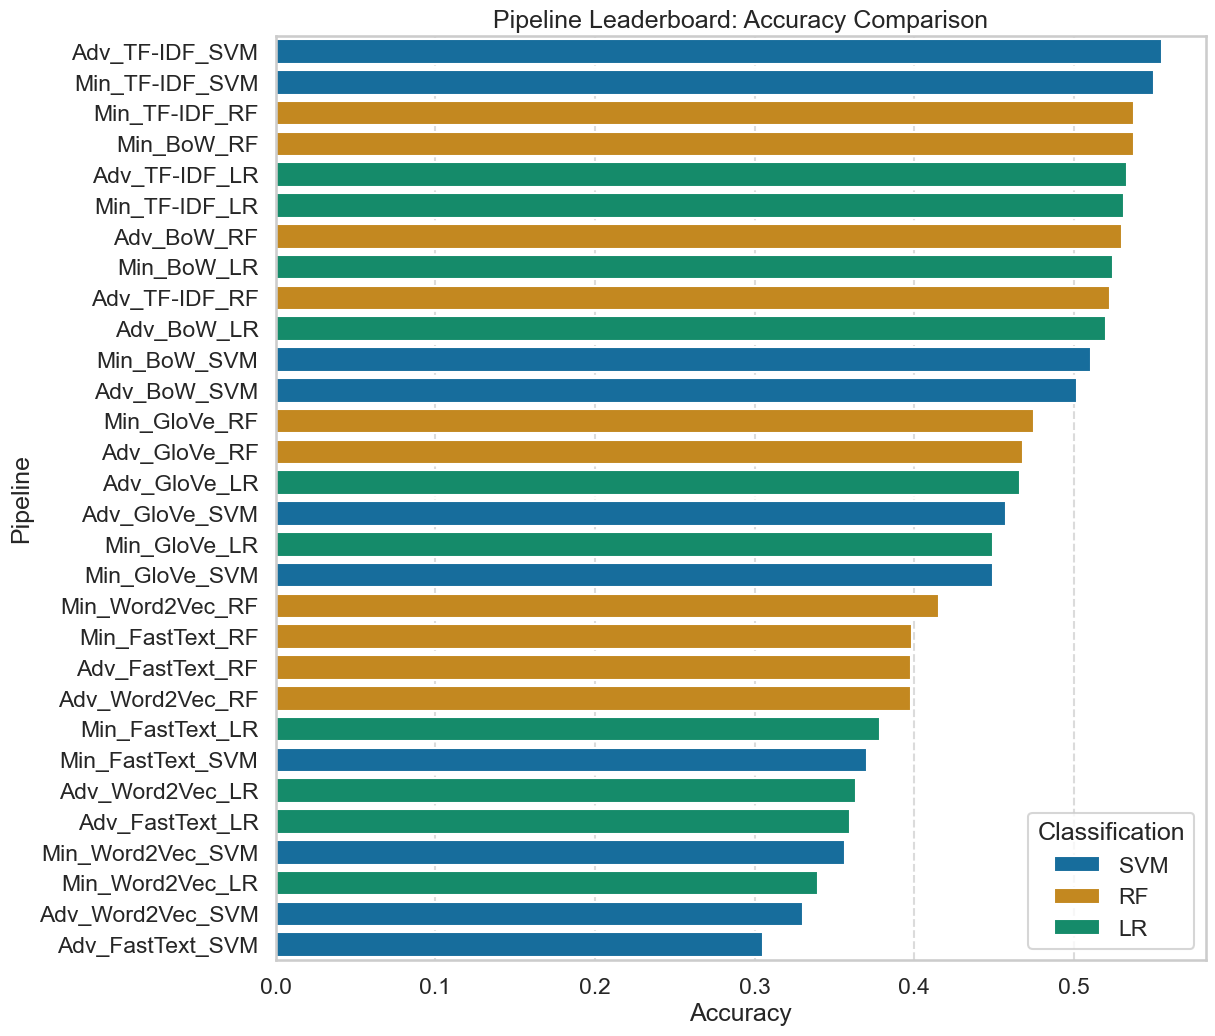

In [34]:
df_sorted = classification_results.sort_values("Accuracy", ascending=False)

plt.figure(figsize=(12, 12))
sb.barplot(data=df_sorted, x="Accuracy", y="Pipeline", hue="Classification", dodge=False)
plt.title("Pipeline Leaderboard: Accuracy Comparison")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.savefig(CHARTS_OUTPUT_PATH + "Classification/Accuracy Pipeline Leaderboard.png", bbox_inches='tight')
plt.show()

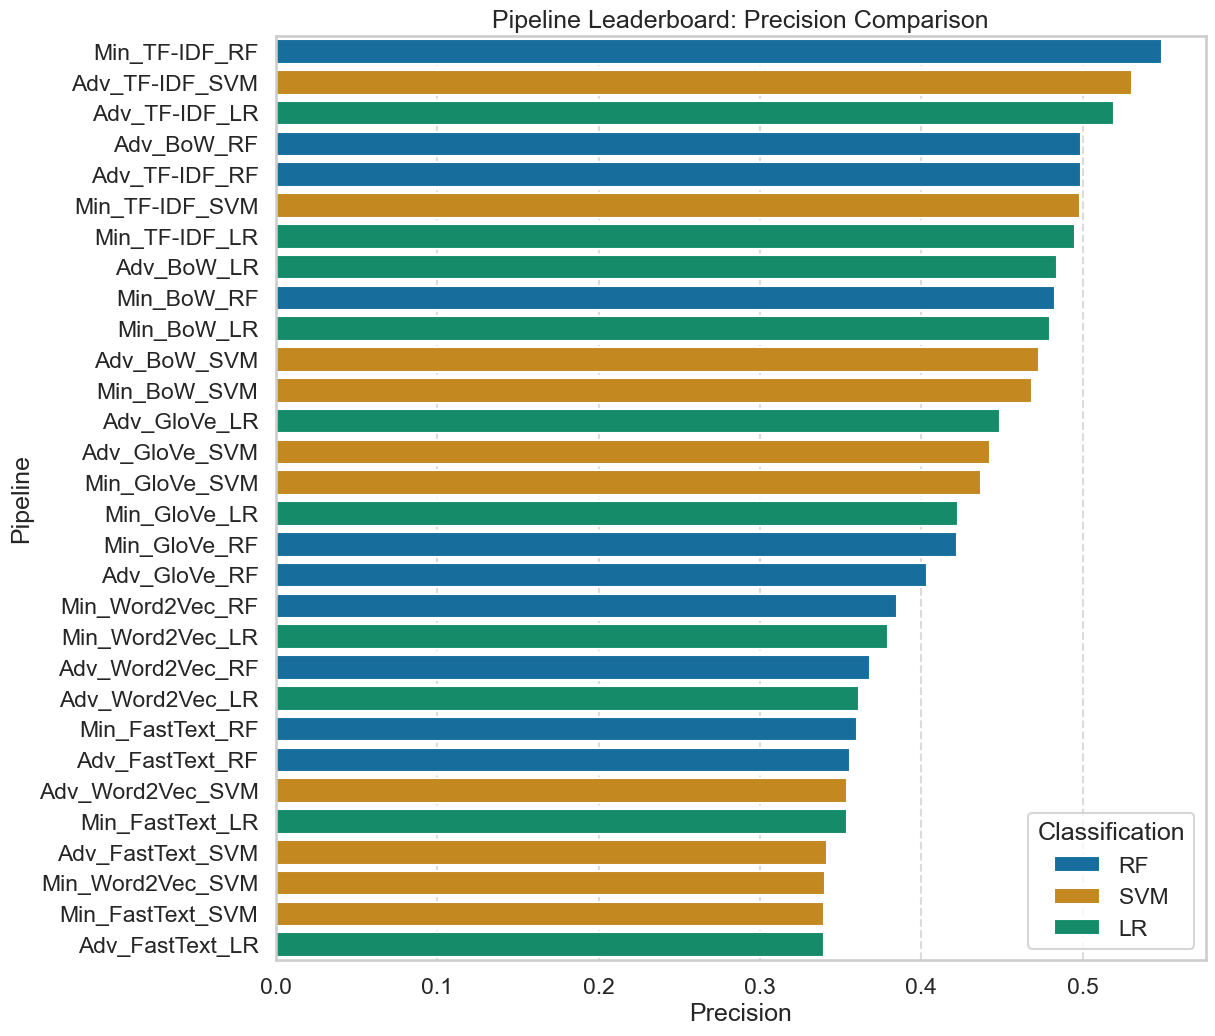

In [35]:
# Tri des résultats par performance décroissante (F1-score)
df_sorted = classification_results.sort_values("Precision", ascending=False)

plt.figure(figsize=(12, 12))
sb.barplot(data=df_sorted, x="Precision", y="Pipeline", hue="Classification", dodge=False)
plt.title("Pipeline Leaderboard: Precision Comparison")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.savefig(CHARTS_OUTPUT_PATH + "Classification/Precision Pipeline Leaderboard.png", bbox_inches='tight')
plt.show()

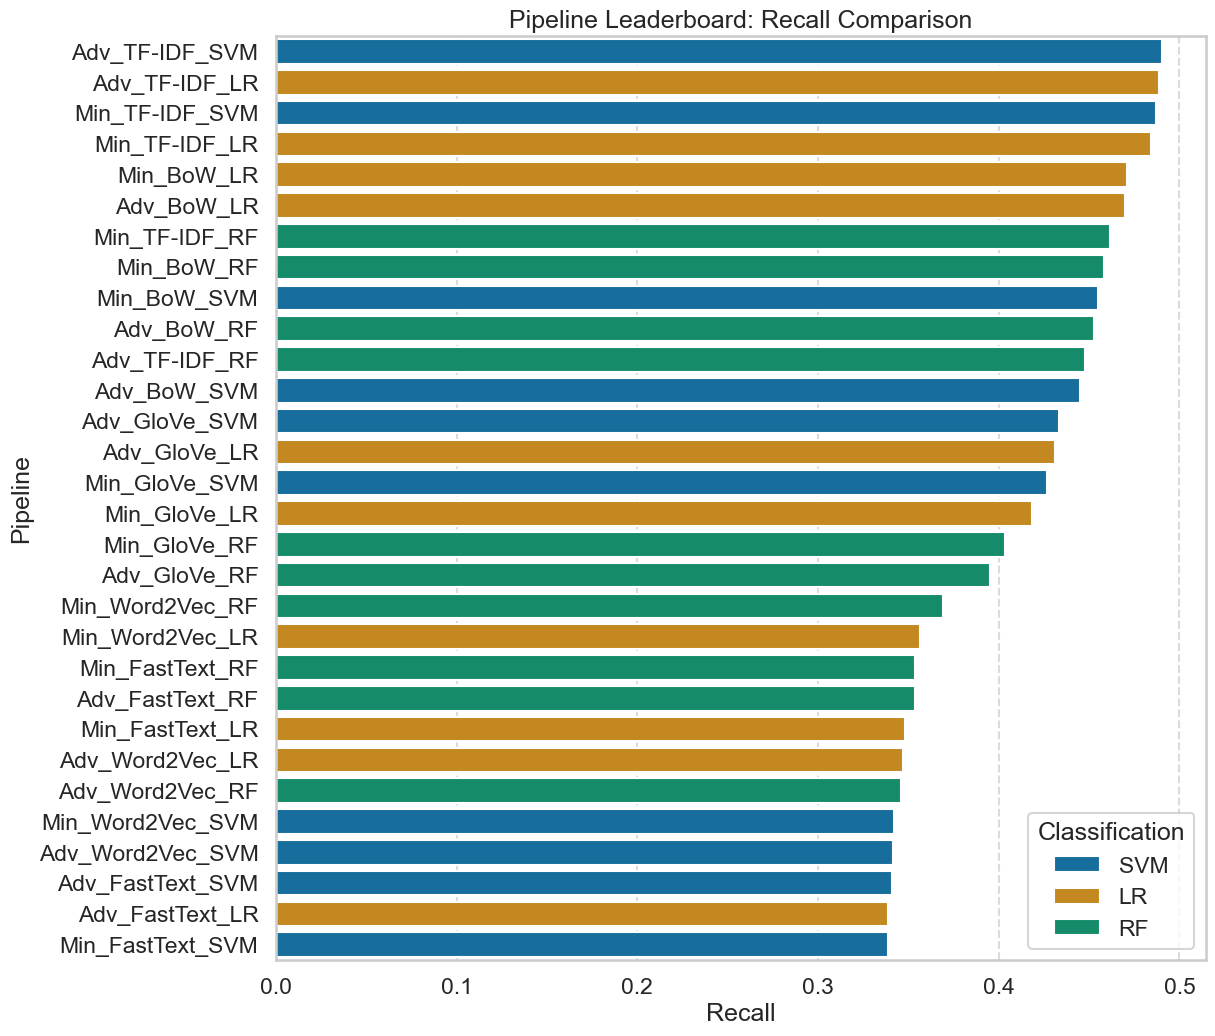

In [36]:
df_sorted = classification_results.sort_values("Recall", ascending=False)

plt.figure(figsize=(12, 12))
sb.barplot(data=df_sorted, x="Recall", y="Pipeline", hue="Classification", dodge=False)
plt.title("Pipeline Leaderboard: Recall Comparison")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.savefig(CHARTS_OUTPUT_PATH + "Classification/Recall Pipeline Leaderboard.png", bbox_inches='tight')
plt.show()

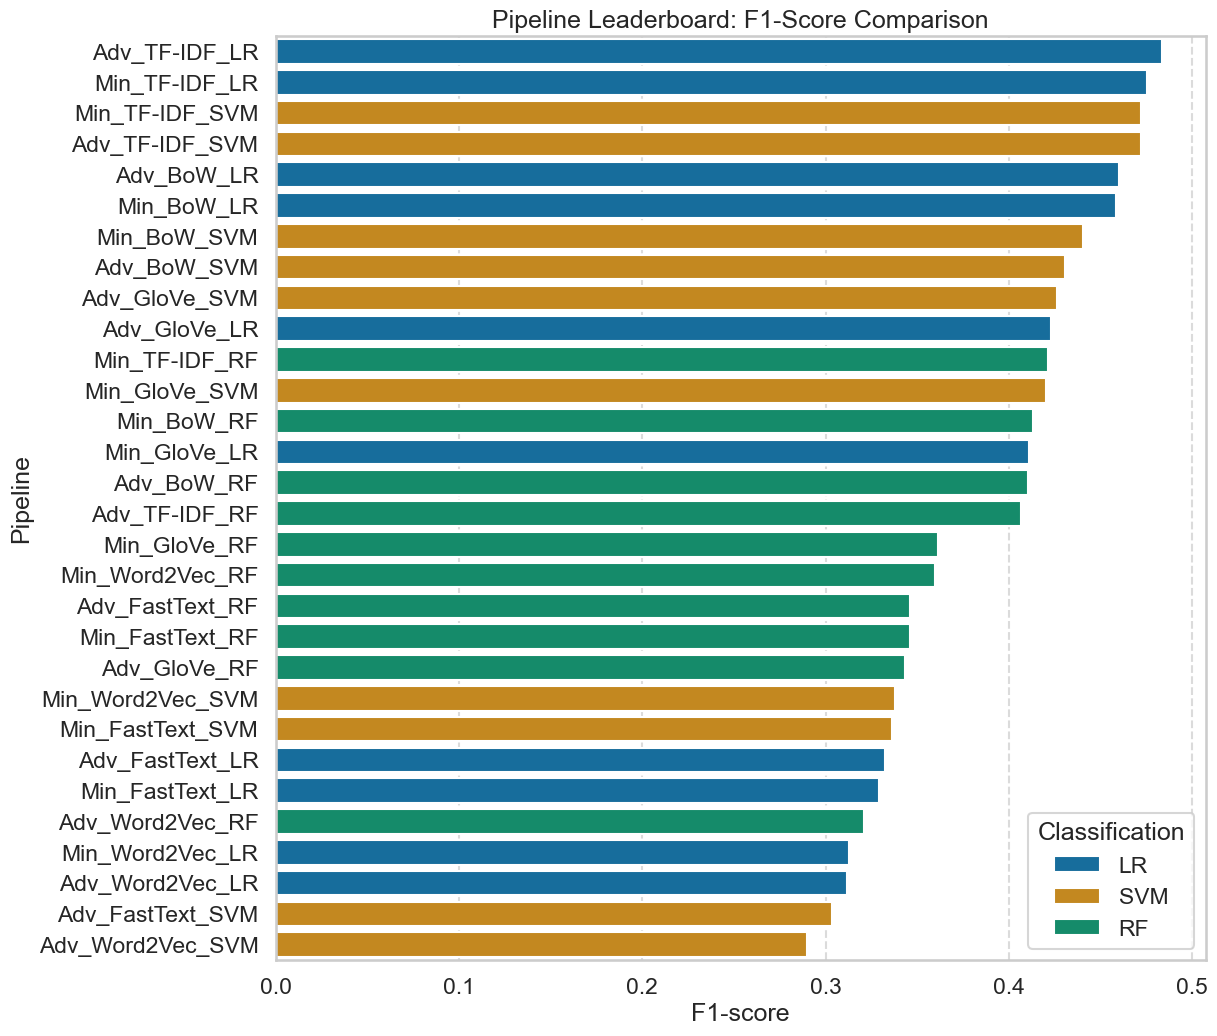

In [37]:
df_sorted = classification_results.sort_values("F1-score", ascending=False)

plt.figure(figsize=(12, 12))
sb.barplot(data=df_sorted, x="F1-score", y="Pipeline", hue="Classification", dodge=False)
plt.title("Pipeline Leaderboard: F1-Score Comparison")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.savefig(CHARTS_OUTPUT_PATH + "Classification/F1-Score Pipeline Leaderboard.png", bbox_inches='tight')
plt.show()

In [38]:
classification_results

,Pipeline,Preprocessing,Vectorization,Classification,Accuracy,Precision,Recall,F1-score,Duration
0,Min_BoW_LR,Min,BoW,LR,0.524444,0.479792,0.470812,0.458419,1.553773
1,Min_BoW_SVM,Min,BoW,SVM,0.511111,0.468357,0.454662,0.440492,4.803320
2,Min_BoW_RF,Min,BoW,RF,0.537778,0.482665,0.458137,0.413340,6.123728
3,Min_TF-IDF_LR,Min,TF-IDF,LR,0.531667,0.495340,0.484375,0.475624,0.981620
4,Min_TF-IDF_SVM,Min,TF-IDF,SVM,0.550000,0.498124,0.487139,0.472391,4.497575
5,Min_TF-IDF_RF,Min,TF-IDF,RF,0.537778,0.548797,0.461372,0.421655,9.532826
6,Min_Word2Vec_LR,Min,Word2Vec,LR,0.340000,0.379035,0.356230,0.312743,1.562365
7,Min_Word2Vec_SVM,Min,Word2Vec,SVM,0.356667,0.340209,0.341967,0.337945,3.204450
8,Min_Word2Vec_RF,Min,Word2Vec,RF,0.415556,0.384631,0.369132,0.359607,5.962955
9,Min_GloVe_LR,Min,GloVe,LR,0.449444,0.422899,0.418371,0.411253,46.476054


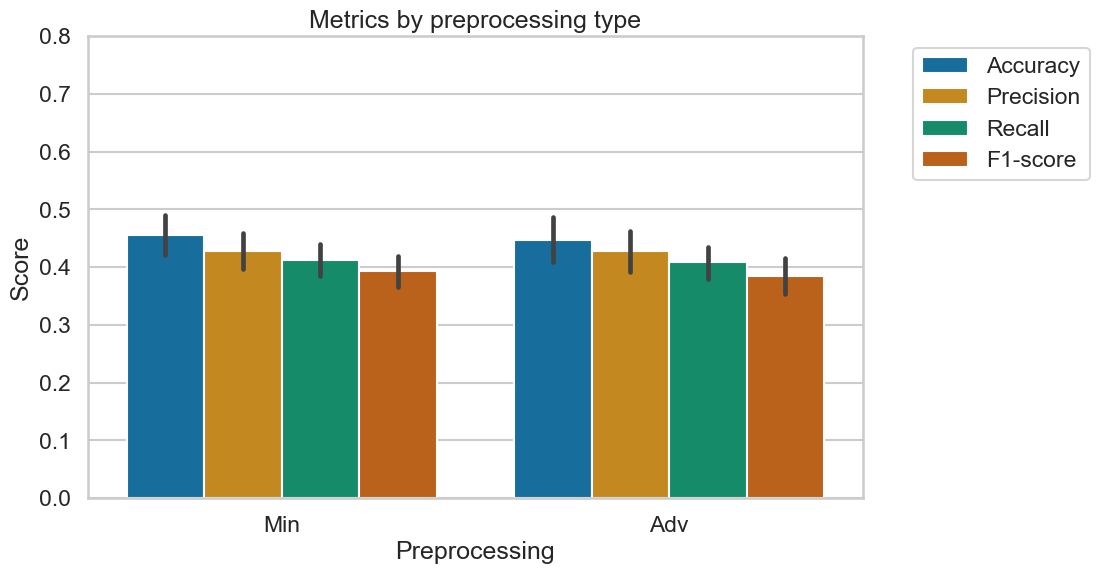

In [39]:
# Préparation des données pour l'affichage groupé (format long)
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
df_plot = classification_results.melt(
    id_vars="Preprocessing",
    value_vars=metrics,
    var_name="Metric",
    value_name="Value"
)

# Comparaison des métriques selon le type de nettoyage
sb.barplot(x="Preprocessing", y="Value", hue="Metric", data=df_plot)
plt.title("Metrics by preprocessing type")
plt.ylabel("Score")
plt.ylim(0, 0.8) # Pour mieux visualiser les différences entre 0 et 1
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Sauvegarde du graphique
plt.savefig(CHARTS_OUTPUT_PATH + "Classification/classifcation_metrics_by_preprocessing.png", bbox_inches='tight')

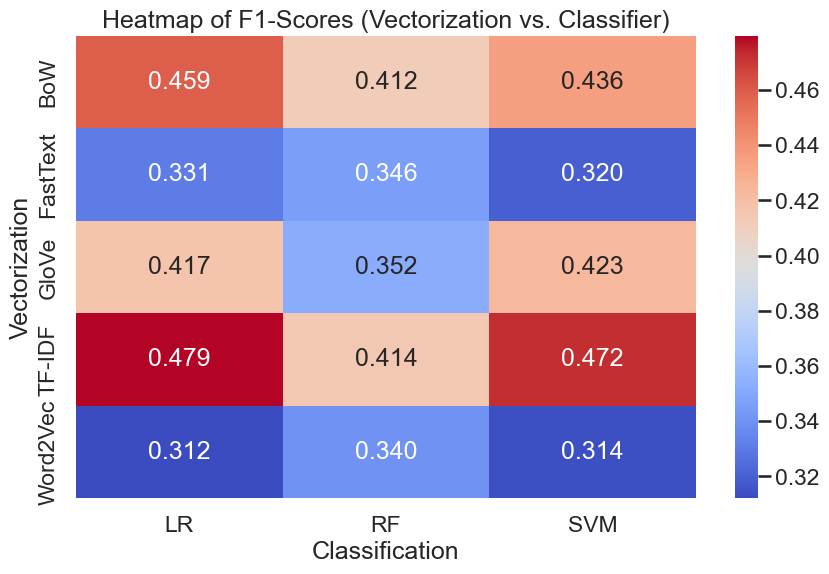

In [40]:
# Création d'un tableau croisé dynamique pour la Heatmap
pivot_df = classification_results.pivot_table(
    index="Vectorization", 
    columns="Classification", 
    values="F1-score"
)

# Configuration de la taille de l'image
plt.rcParams["figure.figsize"] = (10, 6)

# Génération de la Heatmap pour comparer les combinaisons Vectorisation/Modèle
sb.heatmap(pivot_df, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Heatmap of F1-Scores (Vectorization vs. Classifier)")

# Sauvegarde du graphique
plt.savefig(CHARTS_OUTPUT_PATH + "Classification/classification_heatmap_f1_scores.png", bbox_inches='tight')

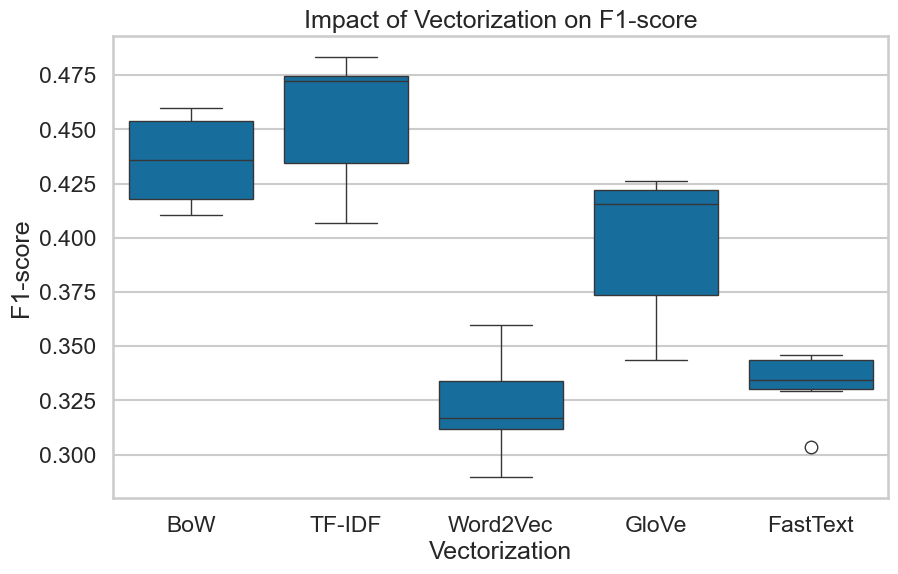

In [41]:
# Analyse de la variance des scores selon la méthode de vectorisation
sb.boxplot(data=classification_results, x="Vectorization", y="F1-score")
plt.title("Impact of Vectorization on F1-score")
plt.savefig(CHARTS_OUTPUT_PATH + "Classification/Impact of Vectorization.png", bbox_inches='tight')

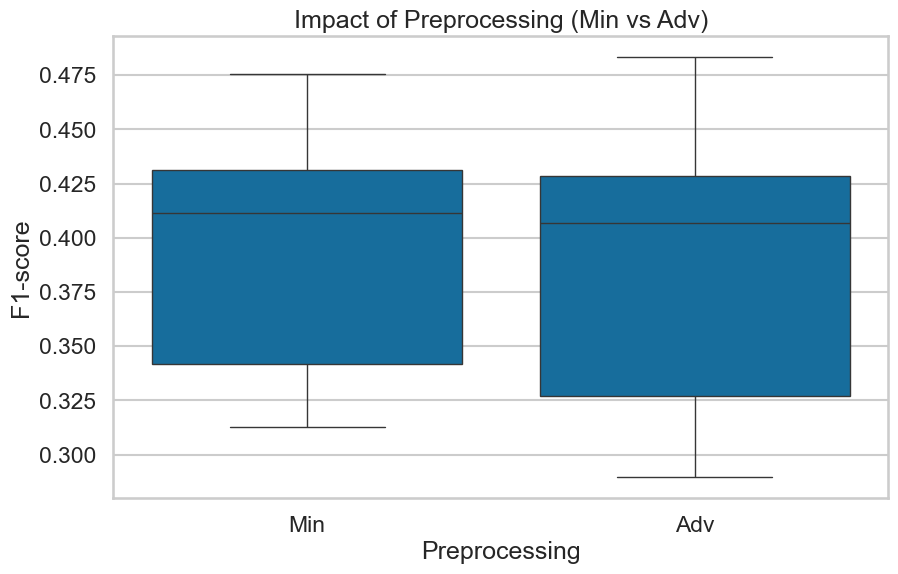

In [42]:
# Analyse de la variance des scores selon le niveau de prétraitement
sb.boxplot(data=classification_results, x="Preprocessing", y="F1-score")
plt.title("Impact of Preprocessing (Min vs Adv)")
plt.savefig(CHARTS_OUTPUT_PATH + "Classification/Impact of Preprocessing.png", bbox_inches='tight')

#### **Verdict :**

**Minimum Preprocessing + TF-IDF + Logistic Regression**

In [71]:
best_classif_pipeline = classif_pipelines["Adv_TF-IDF_SVM"]

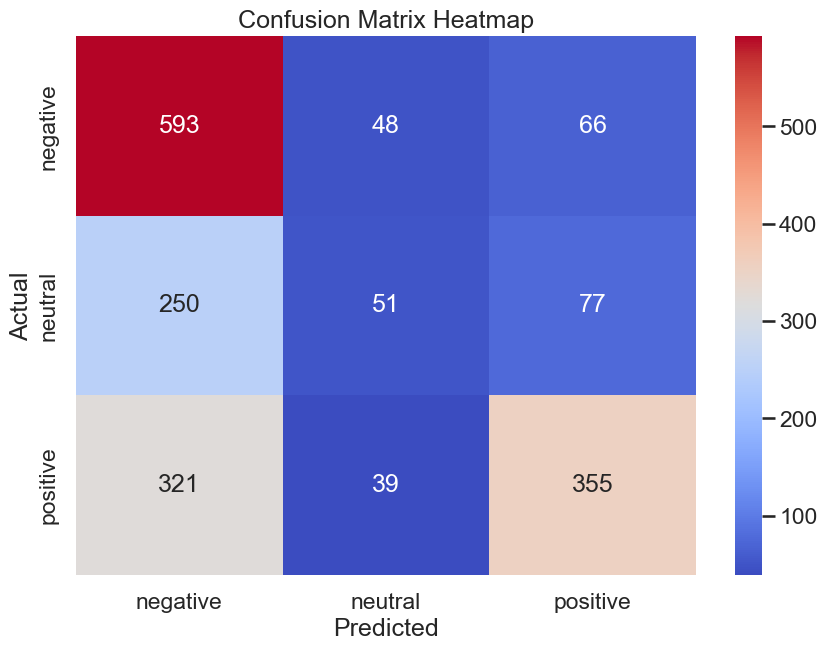

In [72]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Get predictions
y_pred = best_classif_pipeline.predict(uncleaned_x_test)

# 2. Compute the matrix
cm = confusion_matrix(uncleaned_y_test, y_pred)
cm_df = pd.DataFrame(cm, index=best_classif_pipeline.classes_, columns=best_classif_pipeline.classes_)

plt.figure(figsize=(10, 7))
sb.heatmap(cm_df, annot=True, fmt='d', cmap='coolwarm')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix Heatmap')
plt.show()

### **PARTIE 4 — TOPIC MODELING**

#### **Méthode Classique (LDA)**

In [45]:
from gensim import corpora, models

# dictionary = corpora.Dictionary(df["text"])

def construct_dict(data, dictionary):
    if len(dictionary) > 0:
        return [dictionary.doc2bow(rev) for rev in data]
    else:
        return []


class LDATransformer(BaseEstimator, TransformerMixin):
    def __init__(self, num_topics=10):
        self.num_topics = num_topics
        self.dictionary = None
        self.model = None
        self.corpus = None
        

    def fit(self, X, y=None):
        # Build dictionary
        self.dictionary = corpora.Dictionary(X)

        # Use your function
        self.corpus = construct_dict(X, self.dictionary)

        self.model = models.LdaModel(
            corpus=self.corpus,
            id2word=self.dictionary,
            num_topics=self.num_topics,
            random_state=100,
            chunksize=1000,
            passes=10,
            iterations=50
        )
        return self

    def transform(self, X):
        self.corpus = construct_dict(X, self.dictionary)

        def get_topic_vector(bow):
            topic_dist = self.model.get_document_topics(bow)

            vec = np.zeros(self.num_topics)
            for topic_id, prob in topic_dist:
                vec[topic_id] = prob

            return vec

        return np.array([get_topic_vector(doc) for doc in self.corpus])

#### **Méthode embedding (BERTopic)**

In [46]:
from sklearn.base import BaseEstimator, TransformerMixin
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
import numpy as np
from transformers import logging
logging.set_verbosity_error()

class BERTopicTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        from bertopic import BERTopic
        self.model = BERTopic(
            language="english",
            calculate_probabilities=True
        )

    def fit(self, X, y=None):
        X = self._ensure_text(X)
        self.topics_, self.probs_ = self.model.fit_transform(X)
        return self

    def transform(self, X):
        X = self._ensure_text(X)
        topics, probs = self.model.transform(X)
        return probs

    def _ensure_text(self, X):
        if isinstance(X[0], list):
            return [" ".join(doc) for doc in X]
        return X

#### **Execution**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from itertools import product
from sklearn.preprocessing import FunctionTransformer

# Définition des étapes de nettoyage
Pretraitement_Dict = {
    "Min": FunctionTransformer(MinProcessing),
    "Adv": FunctionTransformer(AdvancedProcessing)
}

TopicModeler_Dict = {
    "BERTopic": BERTopicTransformer(),
    "LDA": LDATransformer()
}

In [48]:
topic_modeling_pipelines = {}

# Génération croisée de toutes les combinaisons de pipelines
for prep_name, modeler_name in product(
    Pretraitement_Dict.keys(),
    TopicModeler_Dict.keys()):
    
    pipeline_name = f"{prep_name}_{modeler_name}"
    
    # Assemblage du pipeline final
    topic_modeling_pipelines[pipeline_name] = Pipeline([
        ("preprocessing", Pretraitement_Dict[prep_name]),
        ("topic_modeler", TopicModeler_Dict[modeler_name])
    ])

In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from gensim.models import CoherenceModel
import torch
from transformers import GPT2LMHeadModel, GPT2Tokenizer
from tqdm import tqdm
import pyLDAvis.gensim_models as gensimvis
import pyLDAvis
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
import numpy as np

def clean_topic_words(topic_words):

    cleaned = []

    for topic in topic_words:

        if not isinstance(topic, list):
            continue

        clean_topic = []

        for w in topic:

            # handle tuples (BERTopic / LDA mixed cases)
            if isinstance(w, tuple):
                w = w[0]

            if isinstance(w, str):
                w = w.strip()
                if len(w) > 0:
                    clean_topic.append(w)

        if len(clean_topic) >= 3:
            cleaned.append(clean_topic)

    return cleaned

def evaluate_coherence(cleaning_method, tm_method, x_train):

    topic_model = pipeline.named_steps["topic_modeler"]

    # -------------------------
    # preprocessing
    # -------------------------
    if cleaning_method == "Min":
        texts = MinProcessing(x_train)
    elif cleaning_method == "Adv":
        texts = AdvancedProcessing(x_train)
    else:
        texts = x_train.tolist()

    # force safe format
    texts = [
        t if isinstance(t, list) else str(t).split()
        for t in texts
    ]
    texts = [t for t in texts if len(t) > 0]

    dictionary = Dictionary(texts)

    # -------------------------
    # LDA coherence
    # -------------------------
    if tm_method == "LDA":

        cm = CoherenceModel(
            model=topic_model.model,
            texts=texts,
            dictionary=dictionary,
            coherence="c_v"
        )

        score = cm.get_coherence()
        return None if np.isnan(score) else score

    # -------------------------
    # BERTopic coherence
    # -------------------------
    elif tm_method == "BERTopic":

        raw_topics = topic_model.model.get_topics()

        topic_words = []

        for t in raw_topics.keys():

            if t == -1:
                continue

            words = topic_model.model.get_topic(t)

            if not words:
                continue

            topic_words.append([w for w, _ in words])

        # NOW clean it
        topic_words = clean_topic_words(topic_words)

        if len(topic_words) == 0:
            return None

    return None

# Fonction pour calculer et organiser les métriques de performance
def save_topicmodeling_metrics(name, chrono, x_train, y_test, y_pred):
    methods = name.split("_")
    preproc = pipeline.named_steps["preprocessing"]
    topic_model = pipeline.named_steps["topic_modeler"]
    tm_method = methods[1]
    results = {
        "Pipeline": name,
        "Preprocessing": methods[0],
        "Topic Modeler": methods[1],
        "Coherence": evaluate_coherence(methods[0], methods[1], x_train),
        "Duration": chrono
    }
    return results

def save_topics_html(pip_name):
    tm_method = pip_name.split(sep="_")[1]
    topic_model = pipeline.named_steps['topic_modeler']
    if tm_method == "LDA":     
        pyLDAvis.enable_notebook()
        vis_data = gensimvis.prepare(topic_model.model, topic_model.corpus, topic_model.dictionary)
        pyLDAvis.save_html(vis_data, CHARTS_OUTPUT_PATH + f"Topic Modeling/{pip_name}_visualization.html")
    elif tm_method == "BERTopic":
        fig = topic_model.model.visualize_topics()
        fig.write_html(CHARTS_OUTPUT_PATH + f"Topic Modeling/{pip_name}_visualization.html")


In [50]:
uncleaned_x_train["text"]

23249    軽く、デザインも良い商品です。 ただ、確かに子供はよく机に手をつくし、手をつくと折れてはいけ...
4990     Die Rasierklingen und auch der Rasierer von Sh...
16511    Il manque les bâtonnets qui étaient décrits da...
3906     Ich habe mir das Produkt gekauft, um meinen We...
8487     After calibrating this extended battery via fu...
                               ...                        
19339    Produit bien arrive conforme a ce que je voula...
25692                              跟描述严重不符 垃圾产品 价格跟产品完全不符合
25519                               这书除了做广告还有啥，不知道出版社怎么会出版
29124                                面料很好，穿起来舒适有型，很愉快的一次购物
3288     Preis Leistung stimmt, wer mehr erwartet, muss...
Name: text, Length: 4200, dtype: str

In [51]:
import time

topic_modeling_results = []

# Boucle d'entraînement et d'évaluation de tous les pipelines
for name, pipeline in topic_modeling_pipelines.items():
    start_time = time.time()
    
    # Entraînement et prédiction
    pipeline.fit(uncleaned_x_train, uncleaned_y_train)
    preproc = pipeline.named_steps["preprocessing"]

    X_test_tokens = preproc.transform(uncleaned_x_test)
    topics = pipeline.named_steps["topic_modeler"].transform(X_test_tokens)
    
    # Calcul du temps d'exécution et stockage des résultats
    end_time = time.time()
    chrono = end_time - start_time
    
    topic_modeling_results.append(save_topicmodeling_metrics(name, chrono, uncleaned_x_train, uncleaned_y_test, y_pred))
    save_topics_html(name)
    print(name, " completed")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Min_BERTopic  completed
Min_LDA  completed
Adv_BERTopic  completed
Adv_LDA  completed


#### **Evaluation**

In [52]:
topic_modeling_results = pd.DataFrame(topic_modeling_results)
topic_modeling_results

,Pipeline,Preprocessing,Topic Modeler,Coherence,Duration
0,Min_BERTopic,Min,BERTopic,NaN,122.636594
1,Min_LDA,Min,LDA,0.742840,8.728514
2,Adv_BERTopic,Adv,BERTopic,NaN,68.393375
3,Adv_LDA,Adv,LDA,0.721767,6.030529


In [53]:
# Exportation des résultats finaux vers un fichier Excel
topic_modeling_results.to_excel("Topic Modeling Results.xlsx")

#### **Verdict :**

**Advanced Preprocessing + BERTopic + Linear Regression**

In [54]:
best_tm_pipeline = topic_modeling_pipelines["Adv_LDA"]

### **PARTIE 5 — SYSTÈME DE RECOMMANDATION**

#### **Approche 1 : (Similarité Uniquement)**

**Text → (TF-IDF / Embeddings) → Cosine Similarity → Recommendations**

In [55]:
from sklearn.metrics.pairwise import cosine_similarity

class CosineSimilarityTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.X_ref_ = X
        return self

    def transform(self, X):
        return cosine_similarity(X, self.X_ref_)

class TopKRecommender(BaseEstimator, TransformerMixin):
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y=None):
        return self

    def transform(self, sim_matrix):
        # argsort descending, skip self (index 0)
        topk = np.argsort(-sim_matrix, axis=1)[:, 1:self.k+1]
        return topk
    

def top_k(sim_matrix, k=5, remove_self=True):
    sim_matrix = np.array(sim_matrix)

    if remove_self:
        np.fill_diagonal(sim_matrix, -np.inf)

    topk = np.argsort(-sim_matrix, axis=1)[:, :k]

    return topk

In [56]:
# Définition des étapes de nettoyage
Pretraitement_Dict = {
    "Min": FunctionTransformer(MinProcessing),
    "Adv": FunctionTransformer(AdvancedProcessing)
}

# Définition des méthodes de mise en vecteur
Vectorization_Dict = {
    "TF-IDF": lambda: TfidfVectorizer(analyzer=lambda x: x, lowercase=False),
    "Word2Vec": lambda: Word2VecTransformer(),
    "GloVe": lambda: GloVeTransformer(glove_file_path=EMBEDDING_PATH + "glove_300.txt"),
    "FastText": lambda: FastTextTransformer()
}


In [57]:
def save_similarity_metrics(name, chrono, sim_matrix):
    methods = name.split("_")

    results = {
        "Pipeline": name,
        "Preprocessing": methods[0],
        "Vectorization": methods[1],
        "Similarity": methods[2],

        # similarity metrics
        "Average Similarity": np.mean(sim_matrix),
        "Max Similarity": np.max(sim_matrix),
        "Min Similarity": np.min(sim_matrix),

        "Duration": chrono
    }

    return results

In [58]:
recommendation_pipelines = {}

# Génération croisée de toutes les combinaisons de pipelines
for prep_name, vect_name in product(
    Pretraitement_Dict.keys(),
    Vectorization_Dict.keys()):
    
    pipeline_name = f"{prep_name}_{vect_name}_cosineSim_topKRecommender"
    
    # Assemblage du pipeline final
    recommendation_pipelines[pipeline_name] = Pipeline([
        ("preprocessing", Pretraitement_Dict[prep_name]),
        ("vectorization", Vectorization_Dict[vect_name]()),
        ("cosineSim", CosineSimilarityTransformer())
    ])

In [59]:
import time

recommendation_results = []
recommendation_matrices = []

# Boucle d'entraînement et d'évaluation de tous les pipelines
for name, pipeline in recommendation_pipelines.items():
    start_time = time.time()
    
    # Fit only on X
    pipeline.fit(uncleaned_x_train)
    
    # Get recommendations
    recs = pipeline.transform(uncleaned_x_test)
    reccom = top_k(recs).tolist()

    end_time = time.time()
    chrono = end_time - start_time
    
    recommendation_matrices.append(reccom)
    recommendation_results.append(save_similarity_metrics(name, chrono, reccom))
    
    print(name, "completed")

Min_TF-IDF_cosineSim_topKRecommender completed
Min_Word2Vec_cosineSim_topKRecommender completed
Min_GloVe_cosineSim_topKRecommender completed
Min_FastText_cosineSim_topKRecommender completed
Adv_TF-IDF_cosineSim_topKRecommender completed
Adv_Word2Vec_cosineSim_topKRecommender completed
Adv_GloVe_cosineSim_topKRecommender completed
Adv_FastText_cosineSim_topKRecommender completed


In [60]:
recommendation_results = pd.DataFrame(recommendation_results)
recommendation_results

,Pipeline,Preprocessing,Vectorization,Similarity,Average Similarity,Max Similarity,Min Similarity,Duration
0,Min_TF-IDF_cosineSim_topKRecommender,Min,TF-IDF,cosineSim,1740.139222,4199,0,0.827033
1,Min_Word2Vec_cosineSim_topKRecommender,Min,Word2Vec,cosineSim,1725.672556,4199,1,1.604955
2,Min_GloVe_cosineSim_topKRecommender,Min,GloVe,cosineSim,843.063333,4196,1,101.874972
3,Min_FastText_cosineSim_topKRecommender,Min,FastText,cosineSim,2062.844333,4199,0,6.583349
4,Adv_TF-IDF_cosineSim_topKRecommender,Adv,TF-IDF,cosineSim,1718.873222,4199,0,1.201104
5,Adv_Word2Vec_cosineSim_topKRecommender,Adv,Word2Vec,cosineSim,1651.825111,4196,1,1.985300
6,Adv_GloVe_cosineSim_topKRecommender,Adv,GloVe,cosineSim,843.063333,4196,1,94.484347
7,Adv_FastText_cosineSim_topKRecommender,Adv,FastText,cosineSim,2091.213000,4199,1,6.037811


In [61]:
# Exportation des résultats finaux vers un fichier Excel
recommendation_results.to_excel("Textual Similarity Results.xlsx")

#### **Verdict :**

**Advanced Processing + TF-IDF + Cosine Similarity**

In [62]:
best_ts_pipeline = recommendation_pipelines["Adv_TF-IDF_cosineSim_topKRecommender"]

In [63]:
print(best_classif_pipeline)
print(best_tm_pipeline)
print(best_ts_pipeline)

Pipeline(steps=[('preprocessing',
                 FunctionTransformer(func=<function AdvancedProcessing at 0x0000024B3BC8F1A0>)),
                ('vectorizer',
                 TfidfVectorizer(analyzer=<function <lambda>.<locals>.<lambda> at 0x0000024B3F567D80>,
                                 lowercase=False)),
                ('classifier', SVC(class_weight='balanced'))])
Pipeline(steps=[('preprocessing',
                 FunctionTransformer(func=<function AdvancedProcessing at 0x0000024B3BC8F1A0>)),
                ('topic_modeler', LDATransformer())])
Pipeline(steps=[('preprocessing',
                 FunctionTransformer(func=<function AdvancedProcessing at 0x0000024B3BC8F1A0>)),
                ('vectorization',
                 TfidfVectorizer(analyzer=<function <lambda>.<locals>.<lambda> at 0x0000024DB3A036A0>,
                                 lowercase=False)),
                ('cosineSim', CosineSimilarityTransformer())])


#### **Approche 2 :**

In [75]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd


def custom_xnor(x, y):
    return 1 - abs(x - y)


# =====================================================
# 1. TEXTUAL SIMILARITY
# =====================================================

def get_text_similarity(query_review, similarity_pipeline, reviews_df):

    query_df = pd.DataFrame({"text": [query_review]})

    preproc = similarity_pipeline.named_steps["preprocessing"]
    vectorizer = similarity_pipeline.named_steps["vectorization"]

    corpus_processed = preproc.transform(reviews_df)
    query_processed = preproc.transform(query_df)

    X_corpus = vectorizer.transform(corpus_processed)
    X_query = vectorizer.transform(query_processed)

    return cosine_similarity(X_query, X_corpus)[0]


# =====================================================
# 2. SENTIMENT SIMILARITY
# =====================================================

def get_sentiment_similarity(query_review, sentiment_pipeline, reviews_df):

    query_df = pd.DataFrame({"text": [query_review]})

    sentiment_map = {
        "positive": 1.0,
        "neutral": 0.5,
        "negative": 0.0
    }

    corpus_sentiments = sentiment_pipeline.predict(reviews_df)

    query_sentiment = sentiment_pipeline.predict(query_df)[0]

    query_score = sentiment_map.get(query_sentiment, 0.5)

    sentiment_scores = np.array([
        custom_xnor(
            sentiment_map.get(pred, 0.5),
            query_score
        )
        for pred in corpus_sentiments
    ])

    return sentiment_scores, corpus_sentiments


# =====================================================
# 3. TOPIC SIMILARITY
# =====================================================

def get_topic_similarity(query_review, topic_pipeline, reviews_df):

    query_df = pd.DataFrame({"text": [query_review]})

    preproc = topic_pipeline.named_steps["preprocessing"]
    topic_model = topic_pipeline.named_steps["topic_modeler"]

    query_topic = topic_model.transform(
        preproc.transform(query_df)
    )[0]

    corpus_topics = topic_model.transform(
        preproc.transform(reviews_df)
    )

    return cosine_similarity([query_topic], corpus_topics)[0]


# =====================================================
# 4. MAIN RECOMMENDER
# =====================================================

def recommend_reviews_and_products(
    query_review,
    sentiment_pipeline,
    topic_pipeline,
    similarity_pipeline,
    reviews_df,
    ts_hp=0.2,
    sa_hp=0.6,
    tm_hp=0.2,
    top_k=5
):
    hp_sum = ts_hp + sa_hp + tm_hp
    
    # TEXTUAL
    sim_scores = get_text_similarity(query_review, similarity_pipeline, reviews_df)

    # SENTIMENT
    sentiment_scores, corpus_sentiments = get_sentiment_similarity(query_review, sentiment_pipeline, reviews_df)

    # TOPICS
    topic_scores = get_topic_similarity(query_review, topic_pipeline, reviews_df)

    # FINAL SCORE
    final_scores = (
        (ts_hp/hp_sum) * sim_scores +
        (sa_hp/hp_sum) * sentiment_scores +
        (tm_hp/hp_sum) * topic_scores
    )

    # TOP REVIEWS
    top_idx = np.argsort(final_scores)[::-1][:top_k]

    similar_reviews = reviews_df.iloc[top_idx].copy()

    similar_reviews["TextSimilarity"] = sim_scores[top_idx]
    similar_reviews["SentimentSimilarity"] = sentiment_scores[top_idx]
    similar_reviews["TopicSimilarity"] = topic_scores[top_idx]
    similar_reviews["FinalScore"] = final_scores[top_idx]

    # PRODUCTS
    recommended_products = (
        similar_reviews[
            ["product_id"]
        ]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    # POSITIVE PRODUCTS
    positive_mask = (corpus_sentiments == "positive")

    positive_scores = (
        ts_hp * sim_scores +
        tm_hp * topic_scores
    )

    positive_scores = np.where(
        positive_mask,
        positive_scores,
        -1
    )

    positive_idx = np.argsort(positive_scores)[::-1][:top_k]

    positive_products = reviews_df.iloc[positive_idx].copy()

    positive_products["PositiveScore"] = positive_scores[positive_idx]

    positive_products = (
        positive_products[
            [
                "product_id",
                "text",
                "PositiveScore"
            ]
        ]
        .drop_duplicates(subset=["product_id"])
        .reset_index(drop=True)
    )

    return {
        "similar_reviews": similar_reviews,
        "recommended_products": recommended_products,
        "positive_product_recommendations": positive_products
    }

In [76]:
results = recommend_reviews_and_products(
    query_review="this phone's battery life is the worst, don't buy it",

    sentiment_pipeline=best_classif_pipeline,
    topic_pipeline=best_tm_pipeline,
    similarity_pipeline=best_ts_pipeline,

    reviews_df=df,

    top_k=5
)

#### **Comparaisons des combinaisons (similarité / sentiment / topics)**

In [77]:
experiment_test_results = {}
test_review = "this phone's battery life is the worst, don't buy it"
experiment_test_results["Similarity"] = recommend_reviews_and_products(
                                            query_review=test_review,
                                            sentiment_pipeline=best_classif_pipeline,
                                            topic_pipeline=best_tm_pipeline,
                                            similarity_pipeline=best_ts_pipeline,
                                            reviews_df=df,
                                            top_k=5,
                                            ts_hp=1,
                                            sa_hp=0,
                                            tm_hp=0,
                                        )
experiment_test_results["Similarity + Sentiment"] = recommend_reviews_and_products(
                                            query_review=test_review,
                                            sentiment_pipeline=best_classif_pipeline,
                                            topic_pipeline=best_tm_pipeline,
                                            similarity_pipeline=best_ts_pipeline,
                                            reviews_df=df,
                                            top_k=5,
                                            ts_hp=0.2,
                                            sa_hp=0.6,
                                            tm_hp=0,
                                        )
experiment_test_results["Similarity + Topic"] = recommend_reviews_and_products(
                                            query_review=test_review,
                                            sentiment_pipeline=best_classif_pipeline,
                                            topic_pipeline=best_tm_pipeline,
                                            similarity_pipeline=best_ts_pipeline,
                                            reviews_df=df,
                                            top_k=5,
                                            ts_hp=0.2,
                                            sa_hp=0,
                                            tm_hp=0.2,
                                        )
experiment_test_results["Similarity + Sentiment + Topic"] = recommend_reviews_and_products(
                                            query_review=test_review,
                                            sentiment_pipeline=best_classif_pipeline,
                                            topic_pipeline=best_tm_pipeline,
                                            similarity_pipeline=best_ts_pipeline,
                                            reviews_df=df,
                                            top_k=5,
                                            ts_hp=0.2,
                                            sa_hp=0.6,
                                            tm_hp=0.2,
                                        )

### **PARTIE 6 — ANALYSE COMPARATIVE GLOBALE**

#### **Prétraitement : Impact sur performances**

##### **Classification :**

In [78]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "Duration"]

# Moyenne des scores par type de preprocessing
avg_results = classification_results.groupby("Preprocessing")[metrics].mean()

# Calcul du pourcentage d'évolution
increase_percent = (
    (avg_results.loc["Adv"] - avg_results.loc["Min"])
    / avg_results.loc["Adv"]
) * 100

# Affichage textuel
print("===== Average Scores by Preprocessing Type =====\n")

for metric in metrics:

    min_score = avg_results.loc["Min", metric]
    adv_score = avg_results.loc["Adv", metric]
    increase = increase_percent[metric]

    print(f"{metric}:")
    print(f"  Min preprocessing : {min_score:.4f}")
    print(f"  Adv preprocessing : {adv_score:.4f}")

    if increase >= 0:
        print(f"  Increase : +{increase:.2f}%\n")
    else:
        print(f"  Decrease : {increase:.2f}%\n")

===== Average Scores by Preprocessing Type =====

Accuracy:
  Min preprocessing : 0.4551
  Adv preprocessing : 0.4474
  Decrease : -1.74%

Precision:
  Min preprocessing : 0.4275
  Adv preprocessing : 0.4280
  Increase : +0.12%

Recall:
  Min preprocessing : 0.4115
  Adv preprocessing : 0.4081
  Decrease : -0.85%

F1-score:
  Min preprocessing : 0.3931
  Adv preprocessing : 0.3841
  Decrease : -2.35%

Duration:
  Min preprocessing : 12.7241
  Adv preprocessing : 12.6988
  Decrease : -0.20%



##### **Topic Modeling :**

In [79]:
metrics = ["Coherence", "Duration"]

# Moyenne des scores par type de preprocessing
avg_results = topic_modeling_results.groupby("Preprocessing")[metrics].mean()

# Calcul du pourcentage d'évolution
increase_percent = (
    (avg_results.loc["Adv"] - avg_results.loc["Min"])
    / avg_results.loc["Adv"]
) * 100

# Affichage textuel
print("===== Average Scores by Preprocessing Type =====\n")

for metric in metrics:

    min_score = avg_results.loc["Min", metric]
    adv_score = avg_results.loc["Adv", metric]
    increase = increase_percent[metric]

    print(f"{metric}:")
    print(f"  Min preprocessing : {min_score:.4f}")
    print(f"  Adv preprocessing : {adv_score:.4f}")

    if increase >= 0:
        print(f"  Increase : +{increase:.2f}%\n")
    else:
        print(f"  Decrease : {increase:.2f}%\n")

===== Average Scores by Preprocessing Type =====

Coherence:
  Min preprocessing : 0.7428
  Adv preprocessing : 0.7218
  Decrease : -2.92%

Duration:
  Min preprocessing : 65.6826
  Adv preprocessing : 37.2120
  Decrease : -76.51%



#### **Vectorisation : Impact sur performance** 

##### **Classification**

In [80]:
classification_results["VectorizationType"] = classification_results["Vectorization"].map({
    "BoW": "Symbolic",
    "TF-IDF": "Symbolic",
    "Word2Vec": "Semantic",
    "GloVe": "Semantic",
    "FastText": "Semantic"
})

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "Duration"]

# Moyenne par type de vectorisation
avg_vec = classification_results.groupby("VectorizationType")[metrics].mean()

# Calcul du pourcentage d'évolution (Semantic vs Symbolic)
increase_percent = (
    (avg_vec.loc["Semantic"] - avg_vec.loc["Symbolic"])
    / avg_vec.loc["Semantic"]
) * 100

print("===== Average Scores by Vectorization Type =====\n")

for metric in metrics:

    symbolic = avg_vec.loc["Symbolic", metric]
    semantic = avg_vec.loc["Semantic", metric]
    change = increase_percent[metric]

    print(f"{metric}:")
    print(f"  Symbolic  : {symbolic:.4f}")
    print(f"  Semantic  : {semantic:.4f}")

    if change >= 0:
        print(f"  Change    : +{change:.2f}%\n")
    else:
        print(f"  Change    : {change:.2f}%\n")

===== Average Scores by Vectorization Type =====

Accuracy:
  Symbolic  : 0.5297
  Semantic  : 0.3990
  Change    : -32.76%

Precision:
  Symbolic  : 0.4982
  Semantic  : 0.3808
  Change    : -30.81%

Recall:
  Symbolic  : 0.4675
  Semantic  : 0.3713
  Change    : -25.90%

F1-score:
  Symbolic  : 0.4455
  Semantic  : 0.3506
  Change    : -27.05%

Duration:
  Symbolic  : 4.8280
  Semantic  : 17.9671
  Change    : +73.13%



#### **Topic Modeler : Impacte sur Performance**

##### **Topic Modeling :**

In [81]:
metrics = ["Coherence", "Duration"]

# Moyenne par type de vectorisation
avg_vec = topic_modeling_results.groupby("Topic Modeler")[metrics].mean()

# Calcul du pourcentage d'évolution (Semantic vs Symbolic)
increase_percent = (
    (avg_vec.loc["LDA"] - avg_vec.loc["BERTopic"])
    / avg_vec.loc["LDA"]
) * 100

print("===== Average Scores by Topic Modeler =====\n")

for metric in metrics:

    symbolic = avg_vec.loc["BERTopic", metric]
    semantic = avg_vec.loc["LDA", metric]
    change = increase_percent[metric]

    print(f"{metric}:")
    print(f"  BERTopic  : {symbolic:.4f}")
    print(f"  LDA  : {semantic:.4f}")

    if change >= 0:
        print(f"  Change    : +{change:.2f}%\n")
    else:
        print(f"  Change    : {change:.2f}%\n")

===== Average Scores by Topic Modeler =====

Coherence:
  BERTopic  : nan
  LDA  : 0.7323
  Change    : nan%

Duration:
  BERTopic  : 95.5150
  LDA  : 7.3795
  Change    : -1194.32%



#### **SYSTÈME DE RECOMMANDATION : Analyse des différents combinaisons de similarité / sentiment / topics**

##### **Similarité**

In [82]:
print(experiment_test_results)

{'Similarity': {'similar_reviews':               product_id   review_id  \
7697  product_en_0815060  en_0604051   
8143  product_en_0481541  en_0519847   
5621  product_en_0952782  en_0213537   
8535  product_en_0027181  en_0917736   
7286  product_en_0351859  en_0715887   

                                                   text language  rating  \
7697  I wish the battery life was good . Also $15 a ...       en       3   
8143  My battery was dying and the capacity was redu...       en       4   
5621       This is crap. Don’t buy it. No instructions.       en       1   
8535  This battery was for a cordless phone we have ...       en       4   
7286  Don't buy! All it will do is irritate you, and...       en       3   

     sentiment product_category  TextSimilarity  SentimentSimilarity  \
7697   neutral            watch        0.315910                  0.5   
8143  positive      electronics        0.305142                  1.0   
5621  negative           beauty        0.277440    

In [83]:
similarity_test = experiment_test_results["Similarity"]


In [84]:

similarity_test["similar_reviews"]


,product_id,review_id,text,language,rating,sentiment,product_category,TextSimilarity,SentimentSimilarity,TopicSimilarity,FinalScore
7697,product_en_0815060,en_0604051,I wish the battery life was good . Also $15 a ...,en,3,neutral,watch,0.315910,0.5,0.964387,0.315910
8143,product_en_0481541,en_0519847,My battery was dying and the capacity was redu...,en,4,positive,electronics,0.305142,1.0,0.975492,0.305142
5621,product_en_0952782,en_0213537,This is crap. Don’t buy it. No instructions.,en,1,negative,beauty,0.277440,1.0,0.983545,0.277440
8535,product_en_0027181,en_0917736,This battery was for a cordless phone we have ...,en,4,positive,office_product,0.273316,0.0,0.981616,0.273316
7286,product_en_0351859,en_0715887,"Don't buy! All it will do is irritate you, and...",en,3,neutral,home,0.260663,0.5,0.983545,0.260663


In [85]:

similarity_test["recommended_products"]


,product_id
0,product_en_0815060
1,product_en_0481541
2,product_en_0952782
3,product_en_0027181
4,product_en_0351859


In [86]:

similarity_test["positive_product_recommendations"]

,product_id,text,PositiveScore
0,product_en_0027181,This battery was for a cordless phone we have ...,0.273316
1,product_en_0393005,This phone mount is pretty great. Feels solid....,0.170948
2,product_en_0289858,The best thing about these phones is the Bluet...,0.170346
3,product_en_0961767,nice colors but the stitching is terrible. I w...,0.164091
4,product_en_0395461,Perfect upgrade comparing to my previous LG phone,0.157223


##### **Similarité + Sentiments**

In [87]:
similarity_sentiment_test = experiment_test_results["Similarity + Sentiment"]


In [88]:

similarity_sentiment_test["similar_reviews"]


,product_id,review_id,text,language,rating,sentiment,product_category,TextSimilarity,SentimentSimilarity,TopicSimilarity,FinalScore
8143,product_en_0481541,en_0519847,My battery was dying and the capacity was redu...,en,4,positive,electronics,0.305142,1.0,0.975492,0.826286
5621,product_en_0952782,en_0213537,This is crap. Don’t buy it. No instructions.,en,1,negative,beauty,0.277440,1.0,0.983545,0.819360
6792,product_en_0988762,en_0742152,The 9v batteries don’t even fit correctly........,en,2,negative,home_improvement,0.210493,1.0,0.986082,0.802623
9853,product_en_0937479,en_0546849,Very good sound quality and stay snugly in the...,en,5,positive,other,0.210261,1.0,0.951285,0.802565
6078,product_en_0020449,en_0911200,We use these in our headlamps and other campin...,en,2,negative,drugstore,0.199141,1.0,0.632340,0.799785


In [89]:

similarity_sentiment_test["recommended_products"]


,product_id
0,product_en_0481541
1,product_en_0952782
2,product_en_0988762
3,product_en_0937479
4,product_en_0020449


In [90]:

similarity_sentiment_test["positive_product_recommendations"]

,product_id,text,PositiveScore
0,product_en_0027181,This battery was for a cordless phone we have ...,0.054663
1,product_en_0393005,This phone mount is pretty great. Feels solid....,0.034190
2,product_en_0289858,The best thing about these phones is the Bluet...,0.034069
3,product_en_0961767,nice colors but the stitching is terrible. I w...,0.032818
4,product_en_0395461,Perfect upgrade comparing to my previous LG phone,0.031445


##### **Similarité + Topic Modeling**

In [91]:
similarity_topic_test = experiment_test_results["Similarity + Topic"]


In [92]:

similarity_topic_test["similar_reviews"]


,product_id,review_id,text,language,rating,sentiment,product_category,TextSimilarity,SentimentSimilarity,TopicSimilarity,FinalScore
8143,product_en_0481541,en_0519847,My battery was dying and the capacity was redu...,en,4,positive,electronics,0.305142,1.0,0.975493,0.640318
7697,product_en_0815060,en_0604051,I wish the battery life was good . Also $15 a ...,en,3,neutral,watch,0.315910,0.5,0.964387,0.640148
5621,product_en_0952782,en_0213537,This is crap. Don’t buy it. No instructions.,en,1,negative,beauty,0.277440,1.0,0.983545,0.630493
8535,product_en_0027181,en_0917736,This battery was for a cordless phone we have ...,en,4,positive,office_product,0.273316,0.0,0.981617,0.627467
7286,product_en_0351859,en_0715887,"Don't buy! All it will do is irritate you, and...",en,3,neutral,home,0.260663,0.5,0.983545,0.622104


In [93]:

similarity_topic_test["recommended_products"]


,product_id
0,product_en_0481541
1,product_en_0815060
2,product_en_0952782
3,product_en_0027181
4,product_en_0351859


In [94]:

similarity_topic_test["positive_product_recommendations"]

,product_id,text,PositiveScore
0,product_en_0027181,This battery was for a cordless phone we have ...,0.250987
1,product_en_0777586,Good buy lasted about 3 years.,0.225069
2,product_en_0961767,nice colors but the stitching is terrible. I w...,0.224618
3,product_en_0042772,Great buy! Some of pieces were off slightly! O...,0.224489
4,product_en_0924313,A decent price on batteries that store's charg...,0.223151


##### **Similarité + Topic Modeling + Sentiments**

In [95]:
similarity_sentiment_topic_test = experiment_test_results["Similarity + Sentiment + Topic"]


In [96]:

similarity_sentiment_topic_test["similar_reviews"]


,product_id,review_id,text,language,rating,sentiment,product_category,TextSimilarity,SentimentSimilarity,TopicSimilarity,FinalScore
8143,product_en_0481541,en_0519847,My battery was dying and the capacity was redu...,en,4,positive,electronics,0.305142,1.0,0.975491,0.856127
5621,product_en_0952782,en_0213537,This is crap. Don’t buy it. No instructions.,en,1,negative,beauty,0.277440,1.0,0.983544,0.852197
6792,product_en_0988762,en_0742152,The 9v batteries don’t even fit correctly........,en,2,negative,home_improvement,0.210493,1.0,0.986081,0.839315
5794,product_en_0158393,en_0582242,My phone will not fast charge with these cable...,en,1,negative,industrial_supplies,0.173656,1.0,0.994481,0.833627
5963,product_en_0486090,en_0298652,"Very cute, but the great battery lasts 20 minu...",en,1,negative,other,0.189683,1.0,0.974487,0.832834


In [97]:

similarity_sentiment_topic_test["recommended_products"]


,product_id
0,product_en_0481541
1,product_en_0952782
2,product_en_0988762
3,product_en_0158393
4,product_en_0486090


In [98]:

similarity_sentiment_topic_test["positive_product_recommendations"]

,product_id,text,PositiveScore
0,product_en_0027181,This battery was for a cordless phone we have ...,0.250986
1,product_en_0777586,Good buy lasted about 3 years.,0.225069
2,product_en_0961767,nice colors but the stitching is terrible. I w...,0.224615
3,product_en_0042772,Great buy! Some of pieces were off slightly! O...,0.224488
4,product_en_0924313,A decent price on batteries that store's charg...,0.223151


# **Analyse des Résultats du Système de Recommandation**

## **1. Impact de l’Analyse de Sentiment**

L’ajout du signal de sentiment améliore significativement la qualité des recommandations.

Avec une approche basée uniquement sur la similarité textuelle, certains avis recommandés possèdent des sentiments différents (positif, neutre ou négatif), ce qui réduit la cohérence globale du système.

En ajoutant l’analyse de sentiment :
- les recommandations deviennent émotionnellement plus cohérentes ;
- les avis négatifs sont davantage associés à des avis négatifs ;
- les avis positifs sont rapprochés d’avis positifs.

On observe également une augmentation des scores finaux des recommandations, ce qui montre une meilleure qualité globale du classement.

L’analyse de sentiment améliore donc :
- la pertinence perçue ;
- la cohérence émotionnelle ;
- l’interprétabilité des recommandations.

---

## **2. Impact du Topic Modeling**

Le Topic Modeling améliore principalement la pertinence thématique des recommandations.

Avec la similarité textuelle seule, les recommandations sont parfois basées sur des mots similaires sans réelle proximité sémantique.

L’ajout du Topic Modeling permet :
- d’identifier les mêmes sujets ou problématiques ;
- de regrouper des avis parlant du même contexte ;
- d’améliorer la compréhension sémantique des avis.

Les scores de similarité thématique obtenus sont très élevés, ce qui indique une forte cohérence entre les avis recommandés.

Le Topic Modeling améliore donc :
- la pertinence sémantique ;
- la cohérence des sujets ;
- la qualité globale des recommandations.

---

## **3. Meilleure Combinaison**

La combinaison la plus performante est :

## **Similarity + Sentiment + Topic**

Cette approche hybride combine :
- la similarité textuelle ;
- la cohérence émotionnelle ;
- la proximité thématique.

Les résultats montrent :
- les meilleurs scores finaux ;
- des recommandations plus cohérentes ;
- une meilleure pertinence qualitative ;
- une meilleure interprétabilité.

Cette combinaison fournit donc le système de recommandation le plus robuste et le plus pertinent.

---

## **4. Différence entre Dataset Mono-langue et Multilingue**

Le comportement du système varie entre les datasets mono-langues et multilingues.

### **Dataset Mono-langue**

Dans un dataset mono-langue :
- les méthodes symboliques comme TF-IDF fonctionnent efficacement ;
- les similarités textuelles sont plus stables ;
- les topics sont plus cohérents.

### **Dataset Multilingue**

Dans un dataset multilingue :
- les méthodes purement textuelles deviennent moins efficaces ;
- les embeddings et BERTopic deviennent plus importants ;
- les signaux sémantiques compensent les différences linguistiques.

Le système hybride devient donc particulièrement utile dans un contexte multilingue, car il permet de mieux capturer le sens global des avis malgré les différences de langue.

### **PARTIE 7 — ANALYSE MÉTIER**

In [100]:
lda_model = best_tm_pipeline.named_steps["topic_modeler"].model

raw_topics = lda_model.show_topics(num_topics=-1, formatted=False)

topic_df = pd.DataFrame([
    {
        "Topic": topic_id,
        "Words": [word for word, _ in words]
    }
    for topic_id, words in raw_topics
])

In [101]:
# =========================
# TOPIC EXTRACTION
# =========================

topic_preproc = best_tm_pipeline.named_steps["preprocessing"]
topic_model = best_tm_pipeline.named_steps["topic_modeler"]

processed_texts = topic_preproc.transform(df)

topics_vectors = topic_model.transform(processed_texts)

# Convert topic vectors to topic ids
topics = np.argmax(topics_vectors, axis=1)

df["topic"] = topics


# =========================
# SENTIMENT PREDICTION
# =========================

df["sentiment_pred"] = best_classif_pipeline.predict(df)


# =========================
# NEGATIVE RATIO PER TOPIC
# =========================

negative_ratio = (
    df.groupby("topic")["sentiment_pred"]
    .apply(lambda x: (x == "negative").mean())
    .sort_values(ascending=False)
)

In [102]:
worst_topic_id = negative_ratio.idxmax()
worst_df = df[df["topic"] == worst_topic_id]
print(f"Worst topic = {worst_topic_id}")
print(f"Negative ratio = {negative_ratio.max():.3f}")
print(f"Number of reviews = {len(worst_df)}")

Worst topic = 0
Negative ratio = 0.614
Number of reviews = 1595


In [103]:
negative_ratio.head(10)

topic
0    0.614420
7    0.508929
6    0.482143
1    0.433981
9    0.420131
3    0.417910
4    0.402572
2    0.387299
5    0.380000
8    0.361702
Name: sentiment_pred, dtype: float64

In [105]:
top_5_ids = negative_ratio.head(5).index.tolist()

topic_df[topic_df["Topic"].isin(top_5_ids)]

,Topic,Words
0,0,"[de, le, la, à, et, pa, pour, je, un, est]"
1,1,"[die, und, nicht, ist, da, ich, der, e, sehr, ..."
6,6,"[reçu, conforme, description, livraison, cher,..."
7,7,"[product, didnt, got, sound, earbuds, new, pay..."
9,9,"[would, like, use, one, get, great, work, colo..."


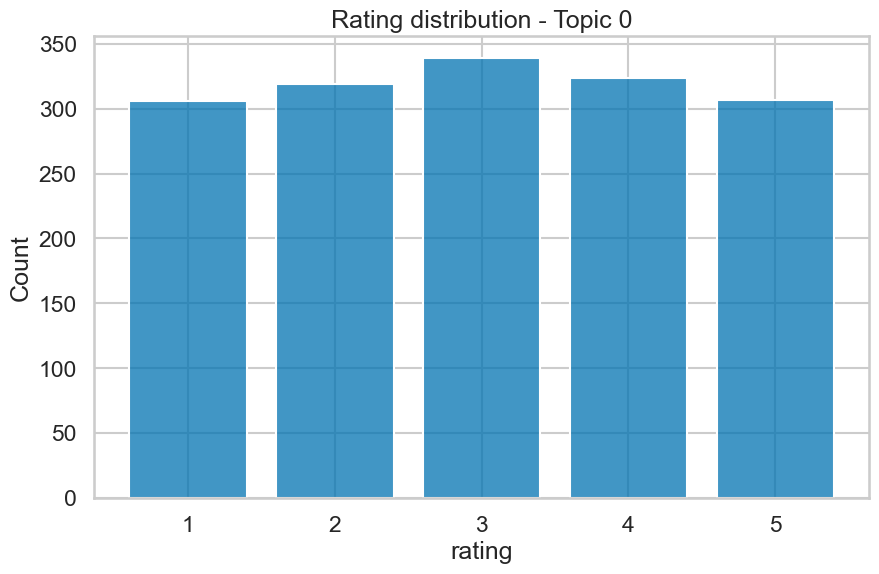

In [106]:
sb.histplot(
    data=worst_df,
    x="rating",
    discrete=True,
    shrink=0.8
)

plt.xticks([1, 2, 3, 4, 5])  # force integer ticks
plt.title(f"Rating distribution - Topic {worst_topic_id}")
plt.show()

### **Quels problèmes clients dominent ?**

Les principaux problèmes détectés concernent :

* les produits cassés ou fragiles,
* les appareils qui arrêtent de fonctionner rapidement,
* la mauvaise qualité des produits,
* les problèmes de remboursement et de retour.

Les mots les plus fréquents dans les topics négatifs sont : *broke*, *broken*, *stopped*, *refund* et *waste money*.

---

### **Quels thèmes génèrent du négatif ?**

Les thèmes les plus associés aux avis négatifs sont :

* les défauts techniques,
* les pannes,
* les produits inefficaces,
* le mauvais service après-vente.

Les topics liés aux produits qui ne fonctionnent pas génèrent le plus de négativité.

---

### **Le multilingue impacte-t-il la compréhension ?**

Oui. Les méthodes classiques comme TF-IDF et LDA sont plus sensibles au multilingue car elles dépendent des mots exacts.
Les méthodes embeddings comme BERTopic gèrent mieux plusieurs langues grâce à la compréhension sémantique.

---

### **Quelle solution recommanderiez-vous en production ?**

La meilleure solution en production serait :

* BERTopic,
* Sentence Embeddings,
* Analyse de sentiment.

Cette combinaison offre :

* de meilleurs topics,
* une meilleure compréhension du multilingue,
* des recommandations plus pertinentes.

Les résultats montrent également que la combinaison :
**Similarity + Sentiment + Topic**
donne les meilleures recommandations.
